# Breast Cancer (BCSC) - Análise

Colunas do arquivo pré-processado (`breast_cancer_screening_bcsc_processed.csv`):

| # | Coluna | O que é | Valores no arquivo processado |
|---|---|---|---|
| 0 | **Age_At_The_Time_Of_Mammography** | Idade da mulher no dia da mamografia | 60 a 89 (anos) |
| 1 | **Radiologists_Assessment** | Conclusão do radiologista ao olhar o exame (escala BI-RADS) | 1 = Negative (nada encontrado), 2 = Benign findings (achado benigno), 3 = Probably benign (provavelmente benigno), 4 = Needs additional imaging (precisa de mais exames), 5 = Suspicious abnormality (suspeito), 6 = Highly suggestive of malignancy (muito provável que seja câncer) |
| 2 | **Is_Binary_Indicator_Of_Cancer_Diagnosis** | **Alvo:** se ela recebeu diagnóstico de câncer de mama em até 1 ano depois do exame | 0 = não, 1 = sim (só 0,65% dos exames) |
| 3 | **Comparison_Mammogram_From_Mammography** | Se havia uma mamografia antiga para o radiologista comparar com a atual | 0 = não, 1 = sim |
| 4 | **Patients_BI_RADS_Breast_Density** | Densidade da mama, ou seja, quanto tecido glandular ela tem em relação a gordura. Mama densa dificulta ver tumores e tem risco um pouco maior | 1 = quase toda gordura, 2 = áreas dispersas de tecido denso, 3 = heterogeneamente densa, 4 = extremamente densa |
| 5 | **Family_History_Of_Breast_Cancer** | Se a mãe, uma irmã ou uma filha teve câncer de mama | 0 = não, 1 = sim |
| 6 | **Current_Use_Of_Hormone_Therapy** | Se ela usava terapia de reposição hormonal na época do exame | 0 = não, 1 = sim |
| 7 | **Binary_Indicator** | Se ela já tinha feito alguma mamografia antes desta. O nome da coluna no arquivo original é genérico mesmo | 0 = não, 1 = sim |
| 8 | **History_Of_Breast_Biopsy** | Se ela já tinha feito biópsia de mama antes | 0 = não, 1 = sim |
| 9 | **Is_Film_Or_Digital_Mammogram** | Tipo de aparelho usado no exame | 0 = filme, 1 = digital |
| 10 | **Patients_Study_ID** | Código que identifica a mulher. **Não é uma feature**: serve só para saber quais exames são da mesma pessoa (algumas fizeram mais de um) | número de identificação |


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../dataset/breast_cancer_screening_bcsc_processed.csv")

In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 39998 entries, 0 to 39997
Data columns (total 11 columns):
 #   Column                                   Non-Null Count  Dtype
---  ------                                   --------------  -----
 0   Age_At_The_Time_Of_Mammography           39998 non-null  int64
 1   Radiologists_Assessment                  39998 non-null  int64
 2   Is_Binary_Indicator_Of_Cancer_Diagnosis  39998 non-null  int64
 3   Comparison_Mammogram_From_Mammography    39998 non-null  int64
 4   Patients_BI_RADS_Breast_Density          39998 non-null  int64
 5   Family_History_Of_Breast_Cancer          39998 non-null  int64
 6   Current_Use_Of_Hormone_Therapy           39998 non-null  int64
 7   Binary_Indicator                         39998 non-null  int64
 8   History_Of_Breast_Biopsy                 39998 non-null  int64
 9   Is_Film_Or_Digital_Mammogram             39998 non-null  int64
 10  Patients_Study_ID                        39998 non-null  int64
dtypes: int64(11)


In [ ]:
# Visão geral da amostra
# Cada linha representa um exame; uma paciente pode ter mais de um exame.
exames_por_paciente = df["Patients_Study_ID"].value_counts()

total_exames = len(df)
total_pacientes = df["Patients_Study_ID"].nunique()
pacientes_com_exames_repetidos = (exames_por_paciente > 1).sum()
exames_adicionais = total_exames - total_pacientes

visao_geral_amostra = pd.DataFrame({
    "Indicador": [
        "Total de exames",
        "Pacientes distintas",
        "Pacientes com mais de um exame",
        "Exames além do primeiro de cada paciente",
    ],
    "Quantidade": [
        total_exames,
        total_pacientes,
        pacientes_com_exames_repetidos,
        exames_adicionais,
    ],
})

visao_geral_amostra


Indicador,Quantidade
Total de exames,39998
Pacientes distintas,36714
Pacientes com mais de um exame,3133
Exames além do primeiro de cada paciente,3284


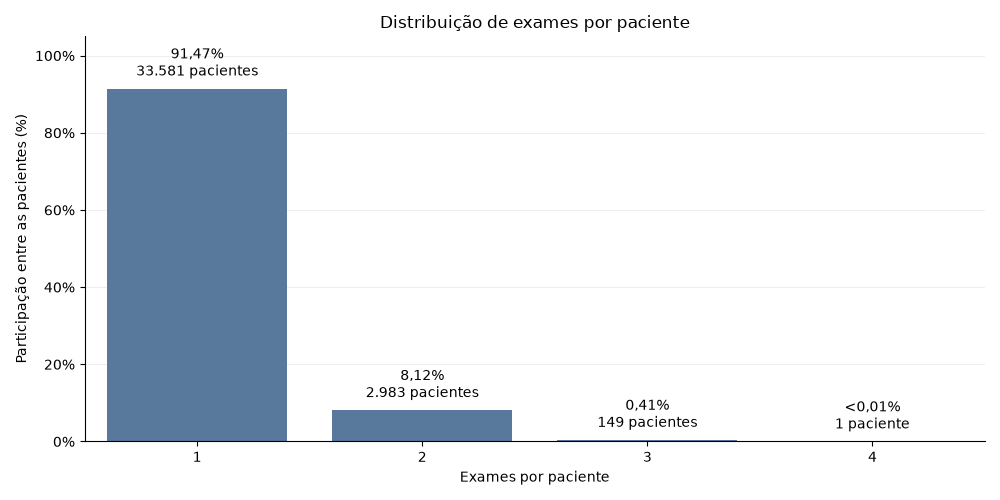

In [ ]:
# Distribuição de exames por paciente
# Cada paciente é contada uma vez; o percentual usa pacientes, não exames.
# A quantidade de exames não informa o intervalo de tempo entre eles.
from matplotlib.ticker import FuncFormatter

frequencia_exames_por_paciente = (
    exames_por_paciente.value_counts().sort_index()
    .rename_axis("Exames por paciente")
    .reset_index(name="Quantidade de pacientes")
)
frequencia_exames_por_paciente["Pacientes (%)"] = (
    frequencia_exames_por_paciente["Quantidade de pacientes"]
    / len(exames_por_paciente) * 100
)

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(
    data=frequencia_exames_por_paciente,
    x="Exames por paciente", y="Pacientes (%)",
    color="#4C78A8", errorbar=None, ax=ax,
)
rotulos_exames_por_paciente = [
    ("<0,01%" if 0 < percentual < 0.01 else f"{percentual:.2f}%".replace(".", ","))
    + f"\n{int(quantidade):,} paciente{'s' if quantidade != 1 else ''}".replace(",", ".")
    for percentual, quantidade in zip(
        frequencia_exames_por_paciente["Pacientes (%)"],
        frequencia_exames_por_paciente["Quantidade de pacientes"],
    )
]
ax.bar_label(ax.containers[0], labels=rotulos_exames_por_paciente, padding=6)
ax.set_title("Distribuição de exames por paciente")
ax.set_xlabel("Exames por paciente")
ax.set_ylabel("Participação entre as pacientes (%)")
ax.set_ylim(0, 105)  # Margem para os rótulos próximos de 100%.
ax.yaxis.set_major_formatter(FuncFormatter(lambda valor, posicao: f"{valor:.0f}%"))
ax.set_axisbelow(True)
ax.yaxis.grid(True, alpha=0.2)
sns.despine(ax=ax)
fig.tight_layout()
plt.show()


In [ ]:
# Valores ausentes na base bruta e tratamento aplicado
# df_bruto é separado do df processado usado nas demais análises.
df_bruto = pd.read_csv("../dataset/breast_cancer_screening_bcsc.csv")

ausencias = df_bruto.isna().sum()
ausencias = ausencias[ausencias > 0].sort_values(ascending=False)

nomes_colunas_ausencias = {
    "Body_Mass_Index": "IMC",
    "Comparison_Mammogram_From_Mammography": "Exame anterior disponível",
    "Current_Use_Of_Hormone_Therapy": "Terapia hormonal",
    "History_Of_Breast_Biopsy": "Biópsia anterior",
    "Binary_Indicator": "Mamografia prévia",
    "Family_History_Of_Breast_Cancer": "Histórico familiar",
}

tratamentos_ausencias = {
    "Body_Mass_Index": "Coluna removida",
    "Comparison_Mammogram_From_Mammography": 'Preenchido com "Sim" (moda)',
    "Current_Use_Of_Hormone_Therapy": 'Preenchido com "Não" (moda)',
    "History_Of_Breast_Biopsy": 'Preenchido com "Não" (moda)',
    "Binary_Indicator": 'Preenchido com "Sim" (moda)',
    "Family_History_Of_Breast_Cancer": 'Preenchido com "Não" (moda)',
}

resumo_ausencias = pd.DataFrame({
    "Coluna": ausencias.index.map(nomes_colunas_ausencias),
    "Quantidade ausente": ausencias.to_numpy(),
    "Percentual ausente (%)": (ausencias / len(df_bruto) * 100).round(2).to_numpy(),
    "Tratamento aplicado": ausencias.index.map(tratamentos_ausencias),
})

resumo_ausencias


Coluna,Quantidade ausente,Percentual ausente (%),Tratamento aplicado
IMC,23208,58.02,Coluna removida
Exame anterior disponível,4680,11.70,"Preenchido com ""Sim"" (moda)"
Terapia hormonal,1772,4.43,"Preenchido com ""Não"" (moda)"
Biópsia anterior,815,2.04,"Preenchido com ""Não"" (moda)"
Mamografia prévia,578,1.45,"Preenchido com ""Sim"" (moda)"
Histórico familiar,228,0.57,"Preenchido com ""Não"" (moda)"


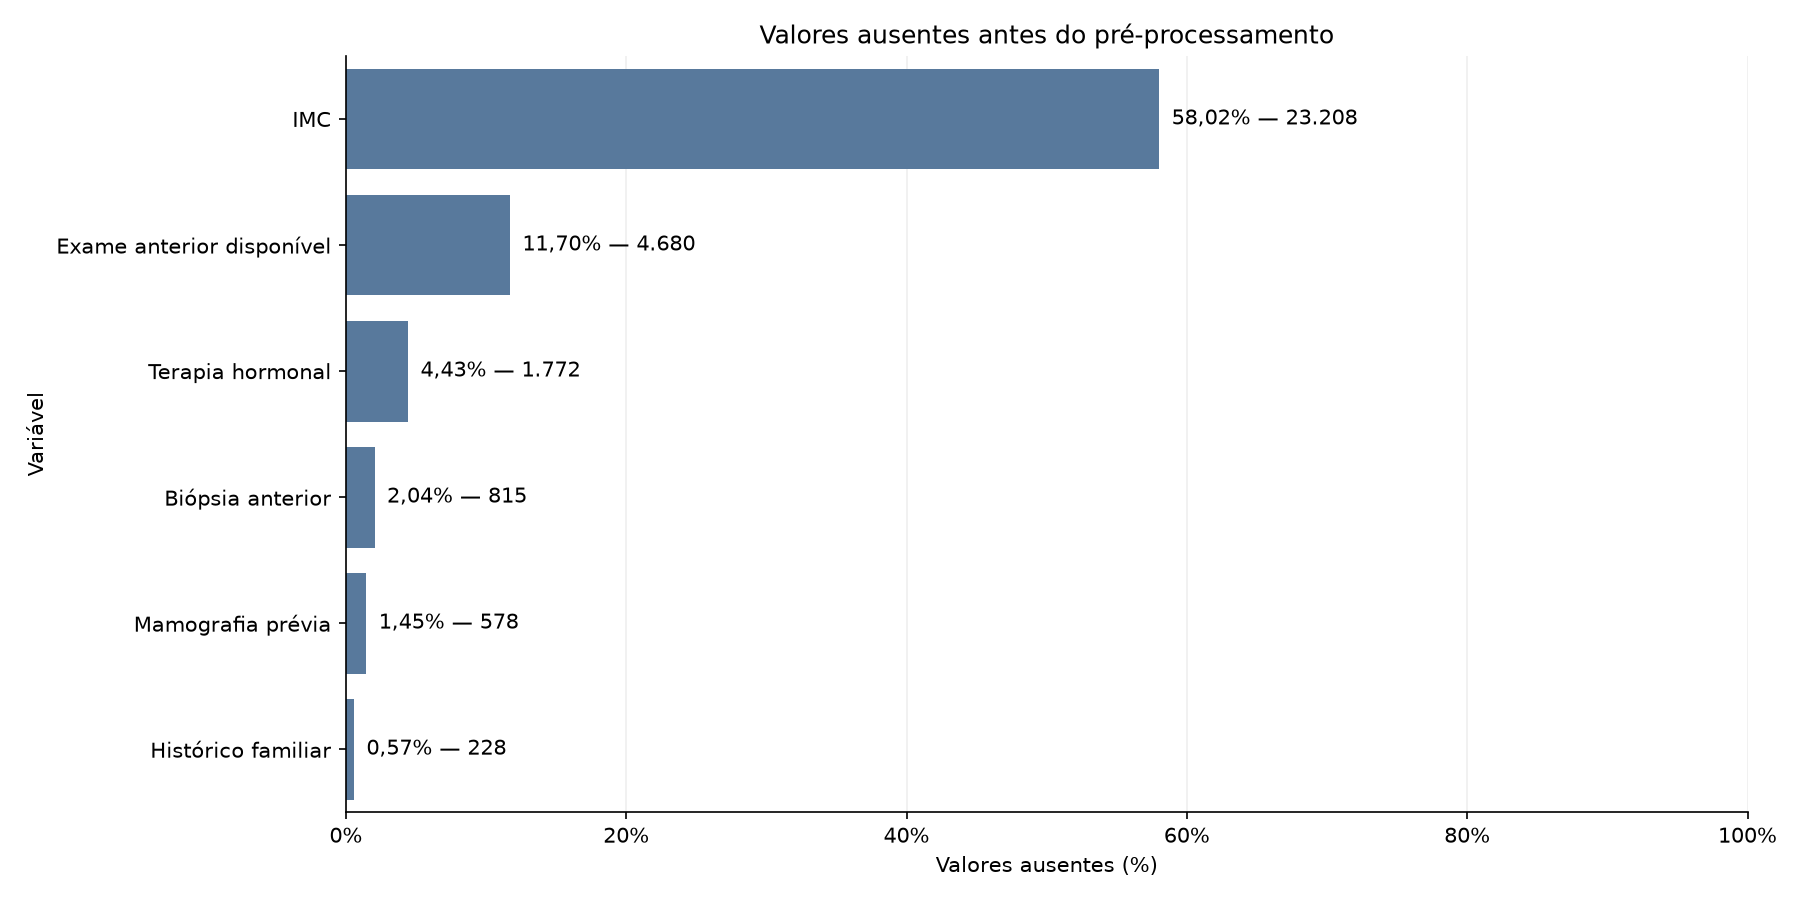

In [ ]:
# Percentual de valores ausentes na base bruta
# Mostra as ausências antes do tratamento, incluindo o IMC que foi removido.
from matplotlib.ticker import FuncFormatter

fig, ax = plt.subplots(figsize=(12, 6))
sns.barplot(
    data=resumo_ausencias,
    x="Percentual ausente (%)",
    y="Coluna",
    order=resumo_ausencias["Coluna"].tolist(),
    orient="h",
    color="#4C78A8",
    errorbar=None,
    ax=ax,
)

rotulos_ausencias_grafico = []
for percentual, quantidade in zip(
    resumo_ausencias["Percentual ausente (%)"],
    resumo_ausencias["Quantidade ausente"],
):
    percentual_formatado = f"{percentual:.2f}".replace(".", ",")
    quantidade_formatada = f"{quantidade:,}".replace(",", ".")
    rotulos_ausencias_grafico.append(
        f"{percentual_formatado}% — {quantidade_formatada}"
    )

ax.bar_label(ax.containers[0], labels=rotulos_ausencias_grafico, padding=6)
ax.set_title("Valores ausentes antes do pré-processamento")
ax.set_xlabel("Valores ausentes (%)")
ax.set_ylabel("Variável")
ax.set_xlim(0, 100)
ax.xaxis.set_major_formatter(
    FuncFormatter(lambda valor, posicao: f"{valor:.0f}%")
)
ax.set_axisbelow(True)
ax.xaxis.grid(True, alpha=0.2)
sns.despine(ax=ax)
fig.tight_layout()
plt.show()


In [3]:
df.loc[df['Age_At_The_Time_Of_Mammography'] > 80, ['Age_At_The_Time_Of_Mammography', 'Is_Binary_Indicator_Of_Cancer_Diagnosis']]

,Age_At_The_Time_Of_Mammography,Is_Binary_Indicator_Of_Cancer_Diagnosis
37,81,0
42,81,0
47,83,0
48,85,0
50,82,0
...,...,...
39929,83,0
39930,84,0
39939,86,0
39942,83,0


In [4]:
df['Age_At_The_Time_Of_Mammography'].describe()

count    39998.000000
mean        69.555703
std          7.202581
min         60.000000
25%         63.000000
50%         68.000000
75%         75.000000
max         89.000000
Name: Age_At_The_Time_Of_Mammography, dtype: float64

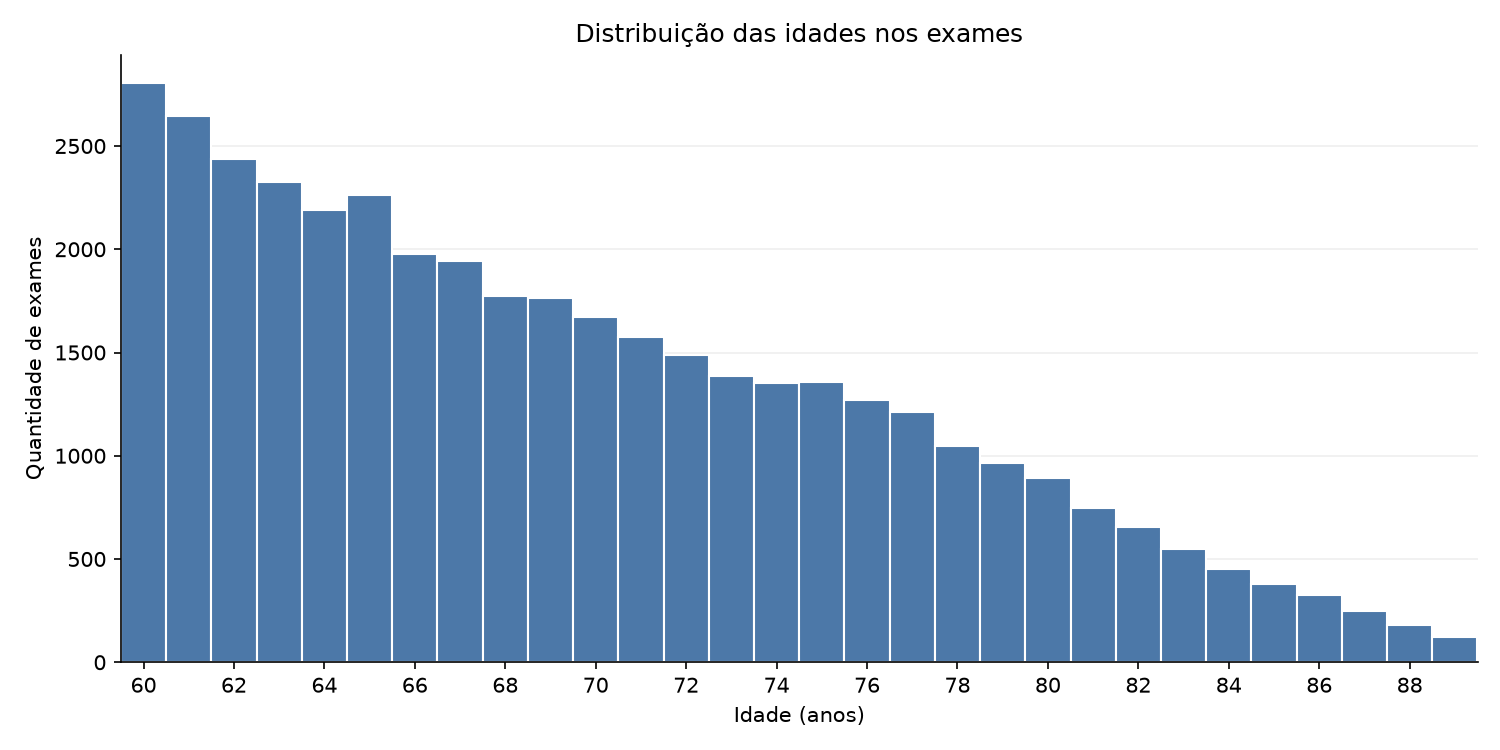

In [ ]:
# Histograma da idade
# Cada barra representa uma idade; a contagem é de exames, não de pacientes distintas.
fig, ax = plt.subplots(figsize=(10, 5))

sns.histplot(
    data=df,
    x="Age_At_The_Time_Of_Mammography",
    discrete=True,
    stat="count",
    color="#4C78A8",
    edgecolor="white",
    alpha=1,
    ax=ax,
)

idade_minima = int(df["Age_At_The_Time_Of_Mammography"].min())
idade_maxima = int(df["Age_At_The_Time_Of_Mammography"].max())
ax.set_xticks(range(idade_minima, idade_maxima + 1, 2))
ax.set_xlim(idade_minima - 0.5, idade_maxima + 0.5)
ax.set_ylim(bottom=0)
ax.set_title("Distribuição das idades nos exames")
ax.set_xlabel("Idade (anos)")
ax.set_ylabel("Quantidade de exames")
ax.set_axisbelow(True)
ax.yaxis.grid(True, alpha=0.2)
sns.despine(ax=ax)
fig.tight_layout()
plt.show()


In [ ]:
# Idade separada por diagnóstico
# As estatísticas são calculadas por exame; uma paciente pode aparecer mais de uma vez.
alvo = "Is_Binary_Indicator_Of_Cancer_Diagnosis"
coluna_idade = "Age_At_The_Time_Of_Mammography"

resumo_idade_por_diagnostico = (
    df.groupby(alvo)[coluna_idade]
    .describe()
    .rename(
        index={0: "Negativo", 1: "Positivo"},
        columns={
            "count": "Quantidade de exames",
            "mean": "Média (anos)",
            "std": "Desvio padrão (anos)",
            "min": "Mínimo (anos)",
            "25%": "1º quartil (anos)",
            "50%": "Mediana (anos)",
            "75%": "3º quartil (anos)",
            "max": "Máximo (anos)",
        },
    )
    .rename_axis("Diagnóstico em até 1 ano")
    .reset_index()
    .round(2)
)

resumo_idade_por_diagnostico["Quantidade de exames"] = (
    resumo_idade_por_diagnostico["Quantidade de exames"].astype(int)
)

resumo_idade_por_diagnostico


Diagnóstico em até 1 ano,Quantidade de exames,Média (anos),Desvio padrão (anos),Mínimo (anos),1º quartil (anos),Mediana (anos),3º quartil (anos),Máximo (anos)
Negativo,39739,69.55,7.20,60.0,63.0,68.0,75.0,89.0
Positivo,259,70.41,7.49,60.0,64.0,69.0,76.0,89.0


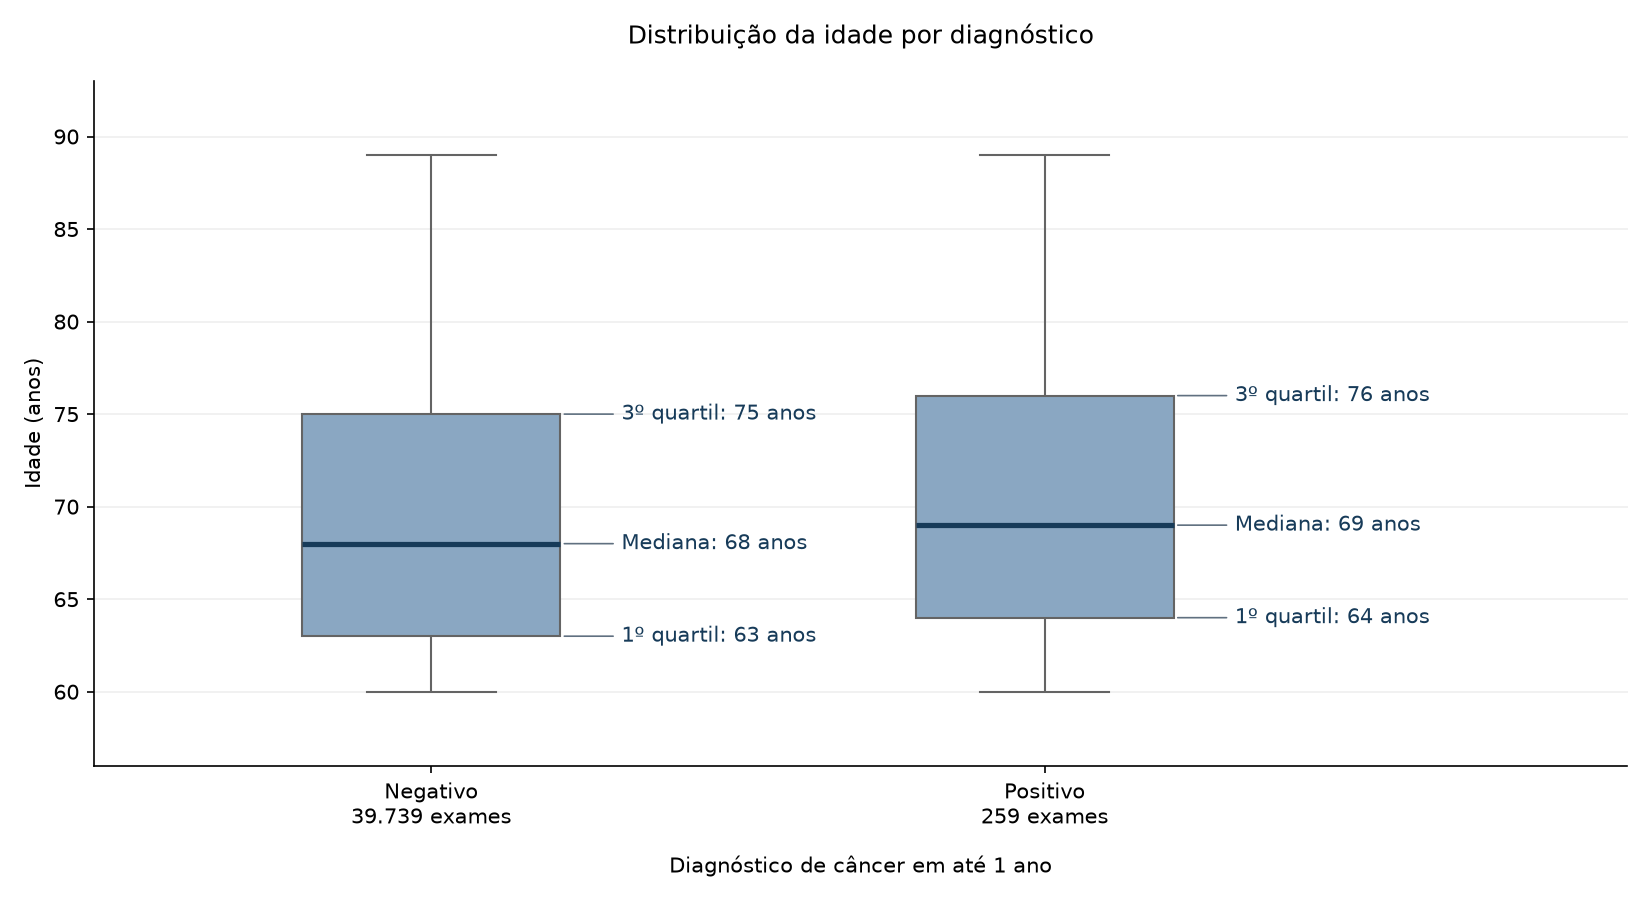

In [ ]:
# Boxplot da idade por diagnóstico
# As caixas resumem idades por exame; sua largura não representa o tamanho dos grupos.
# As hastes usam o limite de 1,5 vezes o intervalo interquartil; pontos indicam valores fora delas.
alvo = "Is_Binary_Indicator_Of_Cancer_Diagnosis"
coluna_idade = "Age_At_The_Time_Of_Mammography"
ordem_diagnostico = ["Negativo", "Positivo"]

dados_idade_diagnostico = df[[alvo, coluna_idade]].copy()
dados_idade_diagnostico["Diagnóstico"] = dados_idade_diagnostico[alvo].map(
    {0: "Negativo", 1: "Positivo"}
)

fig, ax = plt.subplots(figsize=(11, 6))
sns.boxplot(
    data=dados_idade_diagnostico,
    x="Diagnóstico",
    y=coluna_idade,
    order=ordem_diagnostico,
    color="#81A8CB",
    width=0.42,
    whis=1.5,
    showfliers=True,
    medianprops={"color": "#173B59", "linewidth": 2.5},
    ax=ax,
)

rotulos_grupos_idade = []
for posicao, diagnostico in enumerate(ordem_diagnostico):
    idades_grupo = dados_idade_diagnostico.loc[
        dados_idade_diagnostico["Diagnóstico"] == diagnostico, coluna_idade
    ]
    quantidade_formatada = f"{len(idades_grupo):,}".replace(",", ".")
    rotulos_grupos_idade.append(f"{diagnostico}\n{quantidade_formatada} exames")

    quartis_idade = idades_grupo.quantile([0.25, 0.5, 0.75])
    for nome, idade in zip(["1º quartil", "Mediana", "3º quartil"], quartis_idade):
        ax.annotate(
            f"{nome}: {idade:.0f} anos",
            xy=(posicao + 0.21, idade),
            xytext=(posicao + 0.31, idade),
            va="center",
            fontsize=10,
            color="#173B59",
            arrowprops={"arrowstyle": "-", "color": "#607080", "lw": 0.8},
        )

ax.set_xticks([0, 1], rotulos_grupos_idade)
ax.set_xlim(-0.55, 1.95)
ax.set_ylim(56, 93)
ax.set_yticks(range(60, 91, 5))
ax.set_title("Distribuição da idade por diagnóstico", pad=18)
ax.set_xlabel("Diagnóstico de câncer em até 1 ano", labelpad=12)
ax.set_ylabel("Idade (anos)")
ax.set_axisbelow(True)
ax.yaxis.grid(True, alpha=0.2)
sns.despine(ax=ax)
fig.tight_layout()
plt.show()


In [ ]:
# Distribuição geral do diagnóstico em até um ano
alvo = "Is_Binary_Indicator_Of_Cancer_Diagnosis"
rotulos_diagnostico = {
    0: "Negativo",
    1: "Positivo",
}

quantidades_diagnostico = df[alvo].value_counts().reindex([0, 1], fill_value=0)

resumo_diagnostico = pd.DataFrame({
    "Diagnóstico em até 1 ano": [rotulos_diagnostico[codigo] for codigo in quantidades_diagnostico.index],
    "Quantidade de exames": quantidades_diagnostico.to_numpy(),
    "Percentual (%)": (quantidades_diagnostico / len(df) * 100).round(2).to_numpy(),
})

resumo_diagnostico


Diagnóstico em até 1 ano,Quantidade de exames,Percentual (%)
Negativo,39739,99.35
Positivo,259,0.65


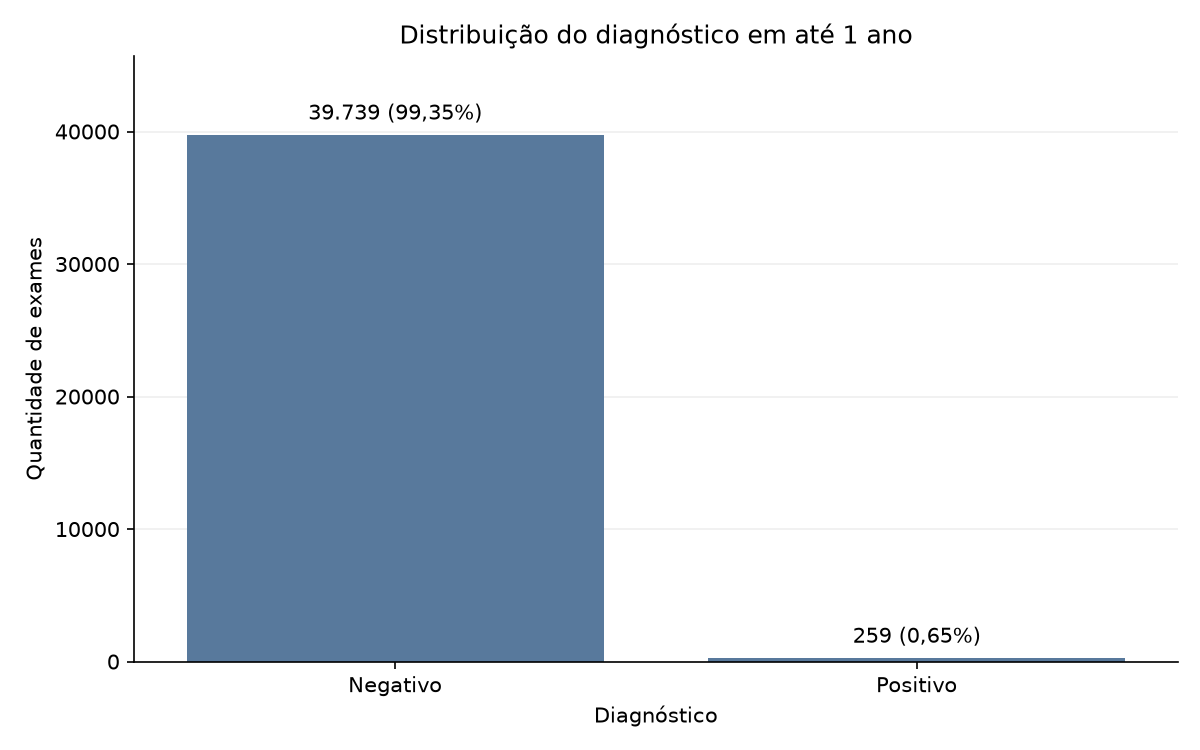

In [ ]:
# Gráfico da distribuição geral do diagnóstico
fig, ax = plt.subplots(figsize=(8, 5))

sns.barplot(
    data=resumo_diagnostico,
    x="Diagnóstico em até 1 ano",
    y="Quantidade de exames",
    order=resumo_diagnostico["Diagnóstico em até 1 ano"].tolist(),
    color="#4C78A8",
    errorbar=None,
    ax=ax,
)

rotulos_diagnostico_grafico = []
for quantidade, percentual in zip(
    resumo_diagnostico["Quantidade de exames"],
    resumo_diagnostico["Percentual (%)"],
):
    quantidade_formatada = f"{quantidade:,}".replace(",", ".")
    percentual_formatado = f"{percentual:.2f}".replace(".", ",")
    rotulos_diagnostico_grafico.append(
        f"{quantidade_formatada} ({percentual_formatado}%)"
    )

ax.bar_label(ax.containers[0], labels=rotulos_diagnostico_grafico, padding=5)
ax.set_title("Distribuição do diagnóstico em até 1 ano")
ax.set_xlabel("Diagnóstico")
ax.set_ylabel("Quantidade de exames")
ax.set_ylim(0, resumo_diagnostico["Quantidade de exames"].max() * 1.15)
ax.set_axisbelow(True)
ax.yaxis.grid(True, alpha=0.2)
sns.despine(ax=ax)
fig.tight_layout()
plt.show()


In [6]:
# 60 anos
mais_60 = df.loc[df['Age_At_The_Time_Of_Mammography'] <= 70, ['Age_At_The_Time_Of_Mammography', 'Is_Binary_Indicator_Of_Cancer_Diagnosis']]

mais_60['Is_Binary_Indicator_Of_Cancer_Diagnosis'].value_counts(normalize=True)


Is_Binary_Indicator_Of_Cancer_Diagnosis
0    0.993904
1    0.006096
Name: proportion, dtype: float64

In [7]:
# 70 anos
mais_70 = df.loc[(df['Age_At_The_Time_Of_Mammography'] > 70) & (df['Age_At_The_Time_Of_Mammography'] <= 80), ['Age_At_The_Time_Of_Mammography', 'Is_Binary_Indicator_Of_Cancer_Diagnosis']]

mais_70['Is_Binary_Indicator_Of_Cancer_Diagnosis'].value_counts(normalize=True)

Is_Binary_Indicator_Of_Cancer_Diagnosis
0    0.993306
1    0.006694
Name: proportion, dtype: float64

In [8]:
# 80 anos
mais_80 = df.loc[df['Age_At_The_Time_Of_Mammography'] > 80, ['Age_At_The_Time_Of_Mammography', 'Is_Binary_Indicator_Of_Cancer_Diagnosis']]

mais_80['Is_Binary_Indicator_Of_Cancer_Diagnosis'].value_counts(normalize=True)

Is_Binary_Indicator_Of_Cancer_Diagnosis
0    0.991808
1    0.008192
Name: proportion, dtype: float64

In [ ]:
alvo = "Is_Binary_Indicator_Of_Cancer_Diagnosis"

faixas = {
    "60–70 anos": mais_60,
    "71–80 anos": mais_70,
    "81–89 anos": mais_80,
}

linhas = []

for faixa, exames in faixas.items():
    total = len(exames)
    negativos = (exames[alvo] == 0).sum()
    positivos = (exames[alvo] == 1).sum()

    linhas.append({
        "Faixa etária": faixa,
        "Total de exames": total,
        "Participação na amostra (%)": total / len(df) * 100,
        "Negativos": negativos,
        "Negativos (%)": negativos / total * 100,
        "Positivos": positivos,
        "Positivos (%)": positivos / total * 100,
    })

resumo_idade_diagnostico = pd.DataFrame(linhas).round(2)
resumo_idade_diagnostico

Faixa etária,Total de exames,Participação na amostra (%),Negativos,Negativos (%),Positivos,Positivos (%)
60–70 anos,23787,59.47,23642,99.39,145,0.61
71–80 anos,12549,31.37,12465,99.33,84,0.67
81–89 anos,3662,9.16,3632,99.18,30,0.82


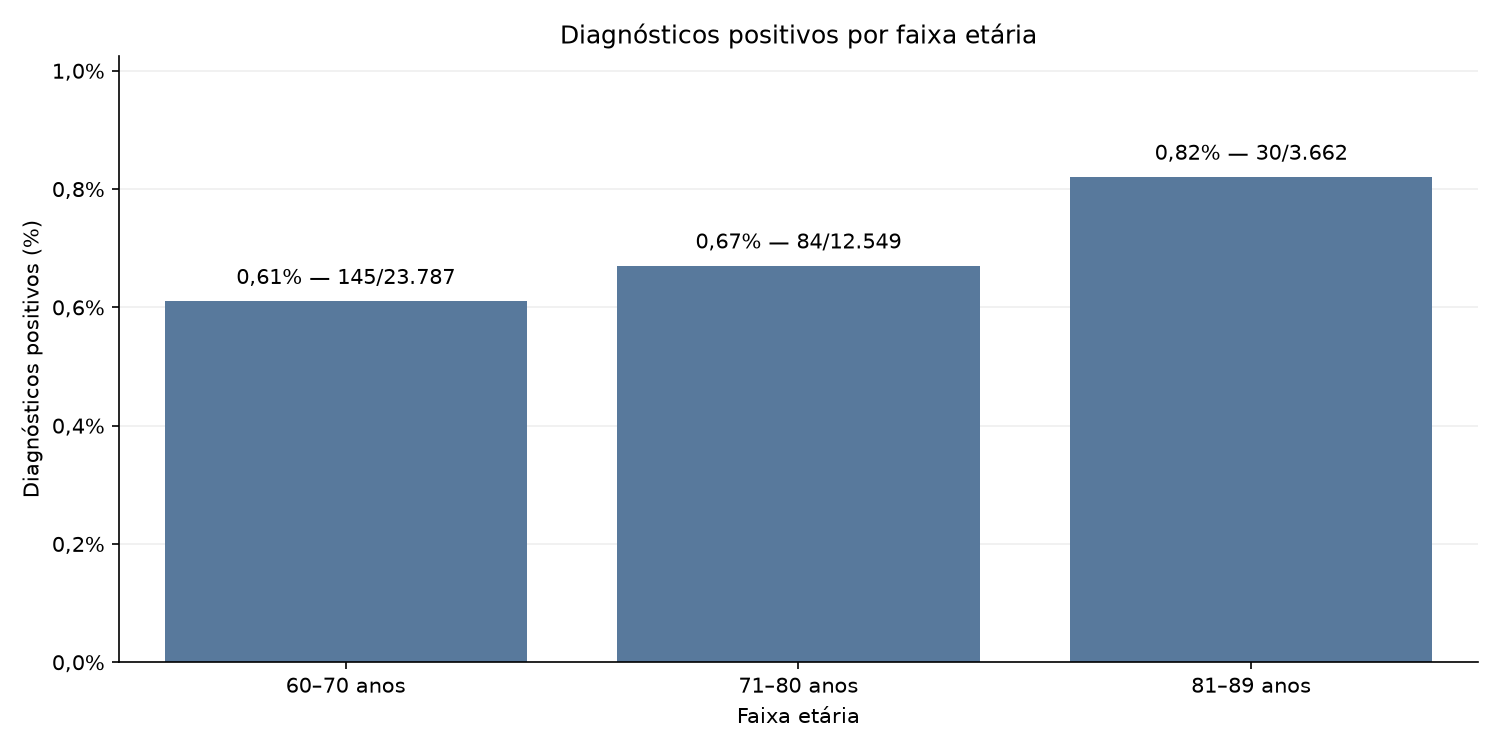

In [ ]:
# Percentual de diagnósticos positivos por faixa etária
from matplotlib.ticker import FuncFormatter

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(
    data=resumo_idade_diagnostico,
    x="Faixa etária",
    y="Positivos (%)",
    order=resumo_idade_diagnostico["Faixa etária"].tolist(),
    color="#4C78A8",
    errorbar=None,
    ax=ax,
)

rotulos_positivos_idade = []
for percentual, positivos, total in zip(
    resumo_idade_diagnostico["Positivos (%)"],
    resumo_idade_diagnostico["Positivos"],
    resumo_idade_diagnostico["Total de exames"],
):
    percentual_formatado = f"{percentual:.2f}".replace(".", ",")
    positivos_formatados = f"{positivos:,}".replace(",", ".")
    total_formatado = f"{total:,}".replace(",", ".")
    rotulos_positivos_idade.append(
        f"{percentual_formatado}% — {positivos_formatados}/{total_formatado}"
    )

ax.bar_label(ax.containers[0], labels=rotulos_positivos_idade, padding=6)
ax.set_title("Diagnósticos positivos por faixa etária")
ax.set_xlabel("Faixa etária")
ax.set_ylabel("Diagnósticos positivos (%)")
ax.set_ylim(0, resumo_idade_diagnostico["Positivos (%)"].max() * 1.25)
# A tabela já contém percentuais: 0,61 representa 0,61%, não 61%.
ax.yaxis.set_major_formatter(
    FuncFormatter(lambda valor, posicao: f"{valor:.1f}%".replace(".", ","))
)
ax.set_axisbelow(True)
ax.yaxis.grid(True, alpha=0.2)
sns.despine(ax=ax)
fig.tight_layout()
plt.show()


In [ ]:
# Densidade mamária x diagnóstico
alvo = "Is_Binary_Indicator_Of_Cancer_Diagnosis"
coluna_densidade = "Patients_BI_RADS_Breast_Density"

categorias_densidade = {
    1: "Quase inteiramente gordurosa",
    2: "Densidades fibroglandulares dispersas",
    3: "Heterogeneamente densa",
    4: "Extremamente densa",
}

linhas_densidade = []

for codigo, categoria in categorias_densidade.items():
    exames = df.loc[df[coluna_densidade] == codigo]
    total = len(exames)
    negativos = (exames[alvo] == 0).sum()
    positivos = (exames[alvo] == 1).sum()

    linhas_densidade.append({
        "Densidade mamária": categoria,
        "Total de exames": total,
        "Participação na amostra (%)": total / len(df) * 100,
        "Negativos": negativos,
        "Negativos (%)": negativos / total * 100,
        "Positivos": positivos,
        "Positivos (%)": positivos / total * 100,
    })

resumo_densidade_diagnostico = pd.DataFrame(linhas_densidade).round(2)
resumo_densidade_diagnostico


Densidade mamária,Total de exames,Participação na amostra (%),Negativos,Negativos (%),Positivos,Positivos (%)
Quase inteiramente gordurosa,5429,13.57,5402,99.50,27,0.50
Densidades fibroglandulares dispersas,21246,53.12,21129,99.45,117,0.55
Heterogeneamente densa,12028,30.07,11920,99.10,108,0.90
Extremamente densa,1295,3.24,1288,99.46,7,0.54


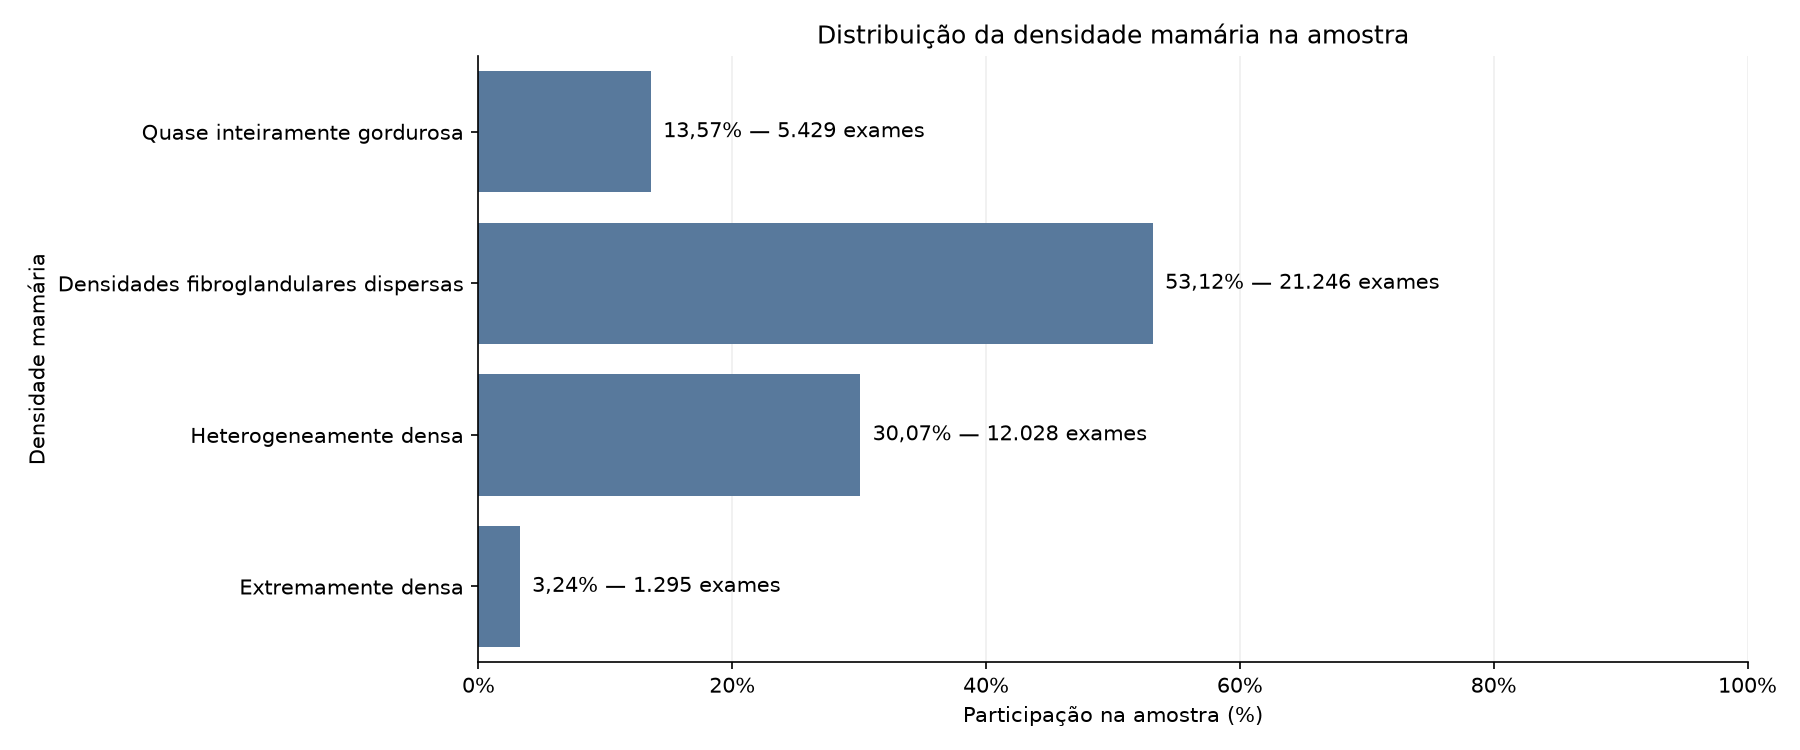

In [ ]:
# Distribuição da densidade mamária na amostra
# O percentual usa todos os exames da amostra, independentemente do diagnóstico.
from matplotlib.ticker import FuncFormatter

fig, ax = plt.subplots(figsize=(12, 5))
sns.barplot(
    data=resumo_densidade_diagnostico,
    x="Participação na amostra (%)",
    y="Densidade mamária",
    order=resumo_densidade_diagnostico["Densidade mamária"].tolist(),
    orient="h",
    color="#4C78A8",
    errorbar=None,
    ax=ax,
)

rotulos_distribuicao_densidade = []
for percentual, quantidade in zip(
    resumo_densidade_diagnostico["Participação na amostra (%)"],
    resumo_densidade_diagnostico["Total de exames"],
):
    percentual_formatado = f"{percentual:.2f}".replace(".", ",")
    quantidade_formatada = f"{quantidade:,}".replace(",", ".")
    rotulos_distribuicao_densidade.append(
        f"{percentual_formatado}% — {quantidade_formatada} exames"
    )

ax.bar_label(ax.containers[0], labels=rotulos_distribuicao_densidade, padding=6)
ax.set_title("Distribuição da densidade mamária na amostra")
ax.set_xlabel("Participação na amostra (%)")
ax.set_ylabel("Densidade mamária")
ax.set_xlim(0, 100)
ax.xaxis.set_major_formatter(
    FuncFormatter(lambda valor, posicao: f"{valor:.0f}%")
)
ax.set_axisbelow(True)
ax.xaxis.grid(True, alpha=0.2)
sns.despine(ax=ax)
fig.tight_layout()
plt.show()


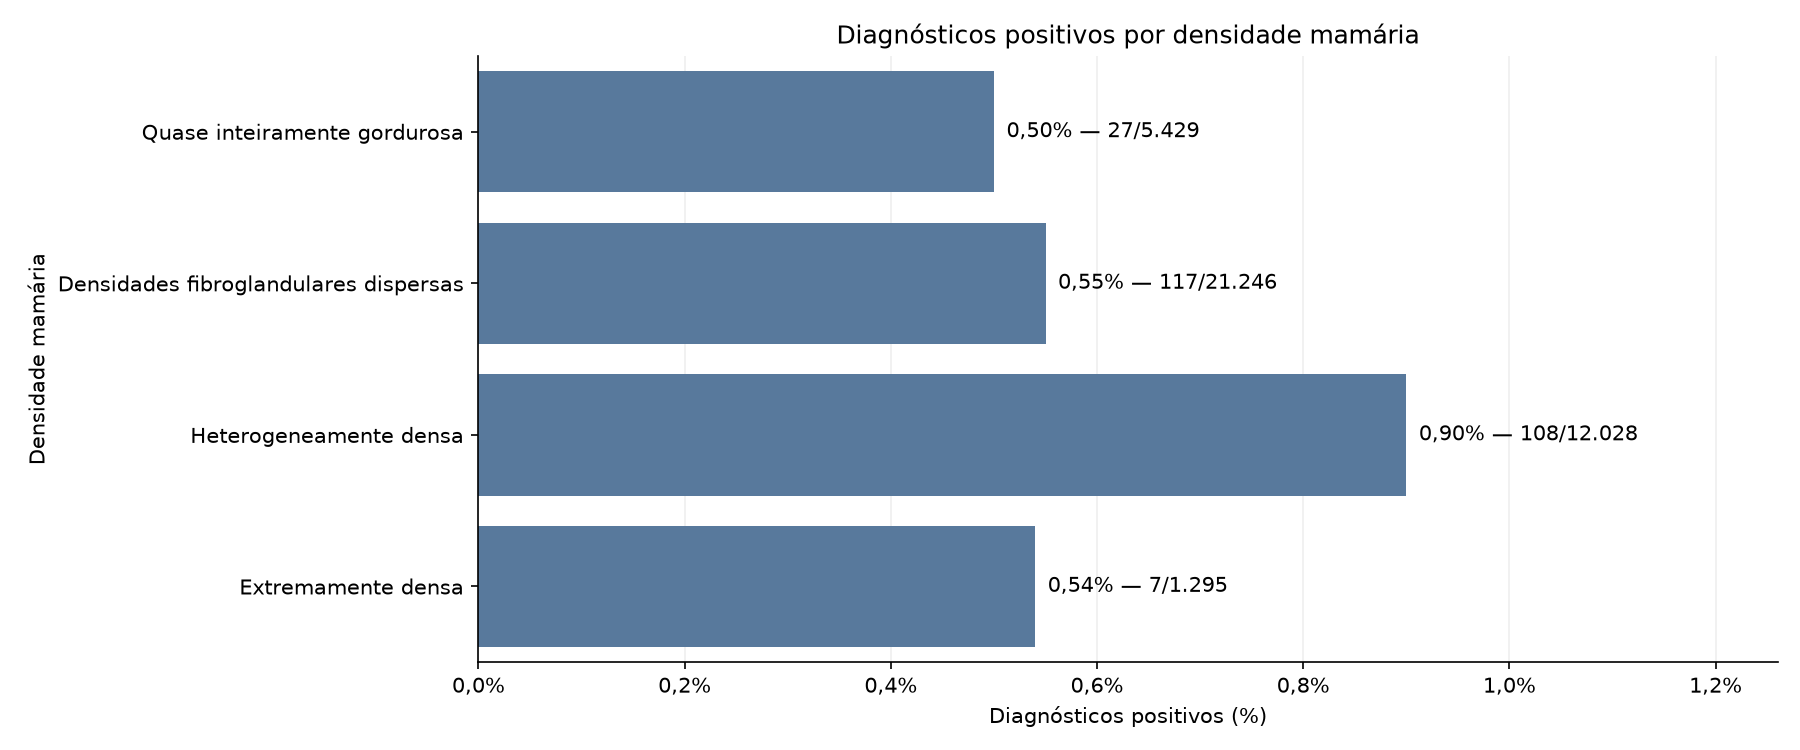

In [ ]:
# Percentual de diagnósticos positivos por densidade mamária
from matplotlib.ticker import FuncFormatter

fig, ax = plt.subplots(figsize=(12, 5))
sns.barplot(
    data=resumo_densidade_diagnostico,
    x="Positivos (%)",
    y="Densidade mamária",
    order=resumo_densidade_diagnostico["Densidade mamária"].tolist(),
    orient="h",
    color="#4C78A8",
    errorbar=None,
    ax=ax,
)

rotulos_positivos_densidade = []
for percentual, positivos, total in zip(
    resumo_densidade_diagnostico["Positivos (%)"],
    resumo_densidade_diagnostico["Positivos"],
    resumo_densidade_diagnostico["Total de exames"],
):
    percentual_formatado = f"{percentual:.2f}".replace(".", ",")
    positivos_formatados = f"{positivos:,}".replace(",", ".")
    total_formatado = f"{total:,}".replace(",", ".")
    rotulos_positivos_densidade.append(
        f"{percentual_formatado}% — {positivos_formatados}/{total_formatado}"
    )

ax.bar_label(ax.containers[0], labels=rotulos_positivos_densidade, padding=6)
ax.set_title("Diagnósticos positivos por densidade mamária")
ax.set_xlabel("Diagnósticos positivos (%)")
ax.set_ylabel("Densidade mamária")
ax.set_xlim(0, resumo_densidade_diagnostico["Positivos (%)"].max() * 1.4)
# Os valores já estão em percentual; a ordem das categorias segue a densidade.
ax.xaxis.set_major_formatter(
    FuncFormatter(lambda valor, posicao: f"{valor:.1f}%".replace(".", ","))
)
ax.set_axisbelow(True)
ax.xaxis.grid(True, alpha=0.2)
sns.despine(ax=ax)
fig.tight_layout()
plt.show()


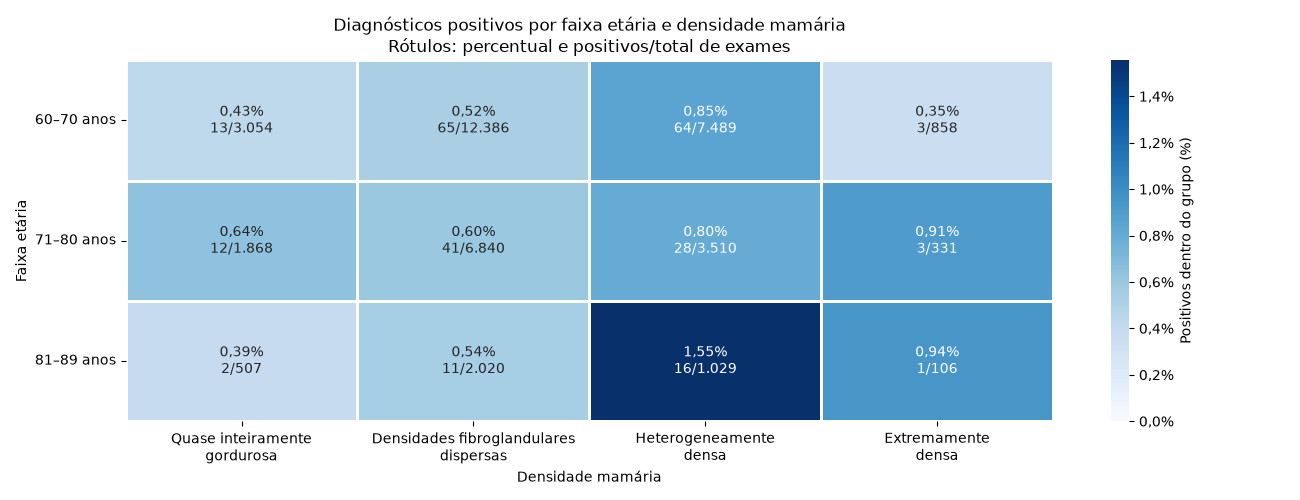

In [ ]:
# Diagnósticos positivos por faixa etária e densidade mamária
# Cada percentual usa os exames da respectiva combinação; não pacientes distintas.
# As contagens contextualizam percentuais baseados em poucos positivos.
from matplotlib.ticker import FuncFormatter

ordem_faixas_idade_densidade = ["60–70 anos", "71–80 anos", "81–89 anos"]
ordem_densidades_idade = list(categorias_densidade.values())
dados_idade_densidade = df.assign(**{
    "Faixa etária": pd.cut(
        df["Age_At_The_Time_Of_Mammography"], bins=[59, 70, 80, 89],
        labels=ordem_faixas_idade_densidade,
    ),
    "Densidade mamária": df["Patients_BI_RADS_Breast_Density"].map(categorias_densidade),
})
resumo_idade_densidade = (
    dados_idade_densidade.groupby(["Faixa etária", "Densidade mamária"], observed=True)
    ["Is_Binary_Indicator_Of_Cancer_Diagnosis"]
    .agg(**{"Total de exames": "size", "Positivos": "sum"})
    .reset_index()
)
resumo_idade_densidade["Positivos (%)"] = (
    resumo_idade_densidade["Positivos"]
    / resumo_idade_densidade["Total de exames"] * 100
)
percentuais_idade_densidade = resumo_idade_densidade.pivot(
    index="Faixa etária", columns="Densidade mamária", values="Positivos (%)"
).reindex(index=ordem_faixas_idade_densidade, columns=ordem_densidades_idade)
rotulos_idade_densidade = pd.DataFrame(
    "", index=percentuais_idade_densidade.index, columns=percentuais_idade_densidade.columns
)
for _, grupo in resumo_idade_densidade.iterrows():
    percentual = f"{grupo['Positivos (%)']:.2f}%".replace(".", ",")
    contagens = f"{int(grupo['Positivos']):,}/{int(grupo['Total de exames']):,}".replace(",", ".")
    rotulos_idade_densidade.loc[grupo["Faixa etária"], grupo["Densidade mamária"]] = (
        f"{percentual}\n{contagens}"
    )

fig, ax = plt.subplots(figsize=(13, 5))
sns.heatmap(
    percentuais_idade_densidade, annot=rotulos_idade_densidade, fmt="",
    cmap="Blues", vmin=0, linewidths=1, linecolor="white",
    cbar_kws={"label": "Positivos dentro do grupo (%)", "format": FuncFormatter(
        lambda valor, posicao: f"{valor:.1f}%".replace(".", ",")
    )}, ax=ax,
)
ax.set_title("Diagnósticos positivos por faixa etária e densidade mamária\nRótulos: percentual e positivos/total de exames")
ax.set_xlabel("Densidade mamária")
ax.set_ylabel("Faixa etária")
ax.set_xticklabels([
    "Quase inteiramente\ngordurosa", "Densidades fibroglandulares\ndispersas",
    "Heterogeneamente\ndensa", "Extremamente\ndensa",
], rotation=0)
ax.tick_params(axis="y", rotation=0)
fig.tight_layout()
plt.show()


In [ ]:
# Histórico familiar x diagnóstico
# No pré-processamento, 228 valores ausentes foram preenchidos com "Não".
alvo = "Is_Binary_Indicator_Of_Cancer_Diagnosis"
coluna_historico_familiar = "Family_History_Of_Breast_Cancer"
categorias_historico_familiar = {0: "Não", 1: "Sim"}

linhas_historico_familiar = []

for codigo, categoria in categorias_historico_familiar.items():
    exames = df.loc[df[coluna_historico_familiar] == codigo]
    total = len(exames)
    negativos = (exames[alvo] == 0).sum()
    positivos = (exames[alvo] == 1).sum()

    linhas_historico_familiar.append({
        "Histórico familiar": categoria,
        "Total de exames": total,
        "Participação na amostra (%)": total / len(df) * 100,
        "Negativos": negativos,
        "Negativos (%)": negativos / total * 100,
        "Positivos": positivos,
        "Positivos (%)": positivos / total * 100,
    })

resumo_historico_familiar = pd.DataFrame(linhas_historico_familiar).round(2)
resumo_historico_familiar


Histórico familiar,Total de exames,Participação na amostra (%),Negativos,Negativos (%),Positivos,Positivos (%)
Não,33255,83.14,33045,99.37,210,0.63
Sim,6743,16.86,6694,99.27,49,0.73


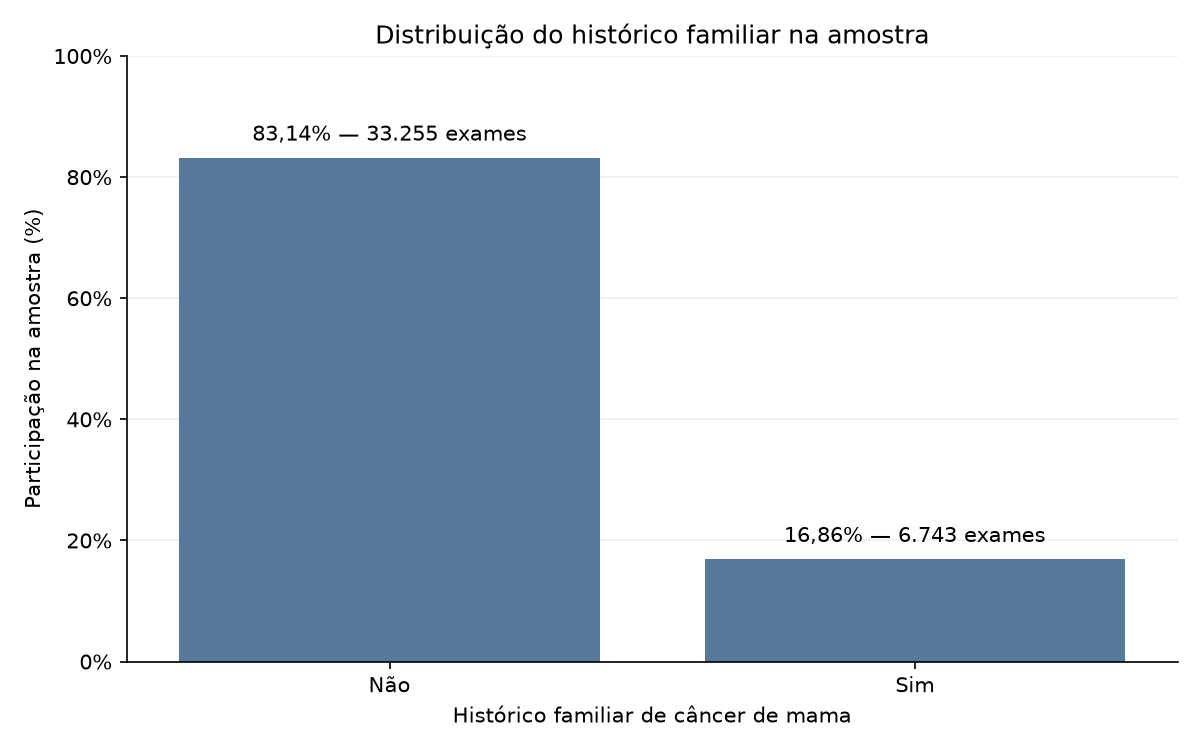

In [ ]:
# Distribuição do histórico familiar na amostra
# O percentual usa todos os exames, independentemente do diagnóstico.
# O grupo "Não" inclui 228 respostas ausentes preenchidas no pré-processamento.
from matplotlib.ticker import FuncFormatter

fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(
    data=resumo_historico_familiar,
    x="Histórico familiar",
    y="Participação na amostra (%)",
    order=resumo_historico_familiar["Histórico familiar"].tolist(),
    color="#4C78A8",
    errorbar=None,
    ax=ax,
)

rotulos_distribuicao_historico_familiar = []
for percentual, quantidade in zip(
    resumo_historico_familiar["Participação na amostra (%)"],
    resumo_historico_familiar["Total de exames"],
):
    percentual_formatado = f"{percentual:.2f}".replace(".", ",")
    quantidade_formatada = f"{quantidade:,}".replace(",", ".")
    rotulos_distribuicao_historico_familiar.append(
        f"{percentual_formatado}% — {quantidade_formatada} exames"
    )

ax.bar_label(ax.containers[0], labels=rotulos_distribuicao_historico_familiar, padding=6)
ax.set_title("Distribuição do histórico familiar na amostra")
ax.set_xlabel("Histórico familiar de câncer de mama")
ax.set_ylabel("Participação na amostra (%)")
ax.set_ylim(0, 100)
ax.yaxis.set_major_formatter(
    FuncFormatter(lambda valor, posicao: f"{valor:.0f}%")
)
ax.set_axisbelow(True)
ax.yaxis.grid(True, alpha=0.2)
sns.despine(ax=ax)
fig.tight_layout()
plt.show()


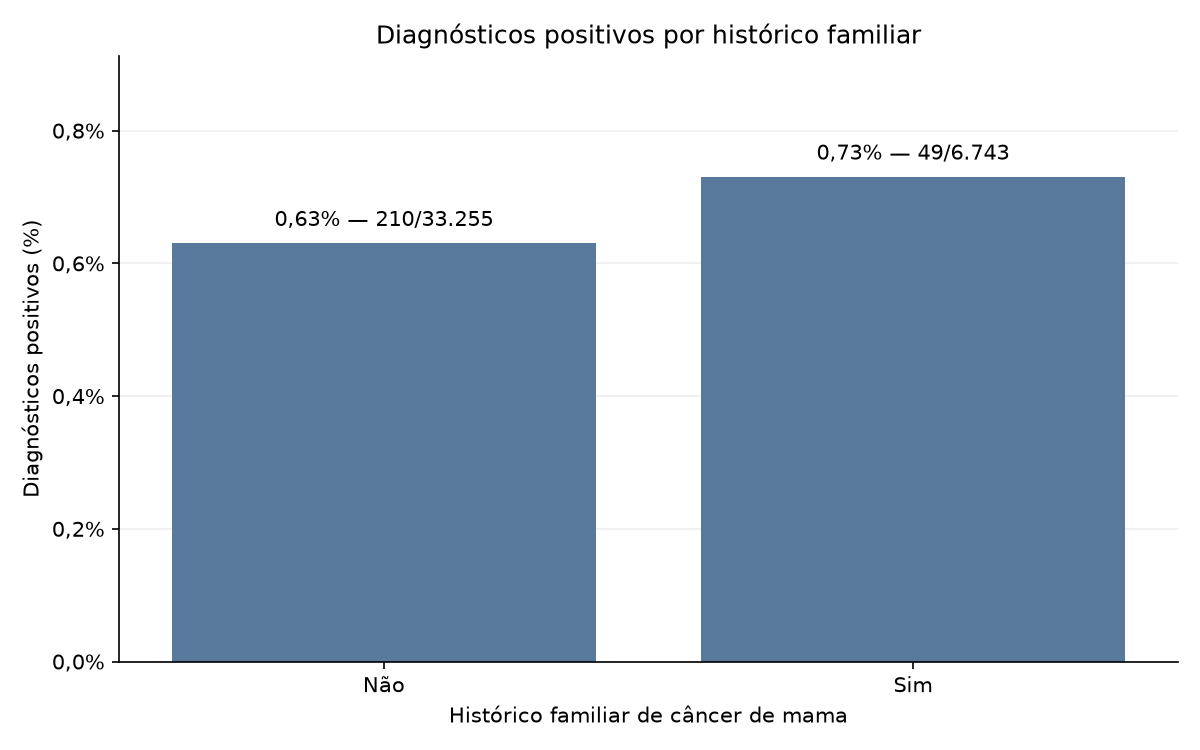

In [ ]:
# Percentual de diagnósticos positivos por histórico familiar
# O grupo "Não" inclui 228 respostas ausentes preenchidas no pré-processamento.
from matplotlib.ticker import FuncFormatter

fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(
    data=resumo_historico_familiar,
    x="Histórico familiar",
    y="Positivos (%)",
    order=resumo_historico_familiar["Histórico familiar"].tolist(),
    color="#4C78A8",
    errorbar=None,
    ax=ax,
)

rotulos_positivos_historico_familiar = []
for percentual, positivos, total in zip(
    resumo_historico_familiar["Positivos (%)"],
    resumo_historico_familiar["Positivos"],
    resumo_historico_familiar["Total de exames"],
):
    percentual_formatado = f"{percentual:.2f}".replace(".", ",")
    positivos_formatados = f"{positivos:,}".replace(",", ".")
    total_formatado = f"{total:,}".replace(",", ".")
    rotulos_positivos_historico_familiar.append(
        f"{percentual_formatado}% — {positivos_formatados}/{total_formatado}"
    )

ax.bar_label(ax.containers[0], labels=rotulos_positivos_historico_familiar, padding=6)
ax.set_title("Diagnósticos positivos por histórico familiar")
ax.set_xlabel("Histórico familiar de câncer de mama")
ax.set_ylabel("Diagnósticos positivos (%)")
ax.set_ylim(0, resumo_historico_familiar["Positivos (%)"].max() * 1.25)
ax.yaxis.set_major_formatter(
    FuncFormatter(lambda valor, posicao: f"{valor:.1f}%".replace(".", ","))
)
ax.set_axisbelow(True)
ax.yaxis.grid(True, alpha=0.2)
sns.despine(ax=ax)
fig.tight_layout()
plt.show()


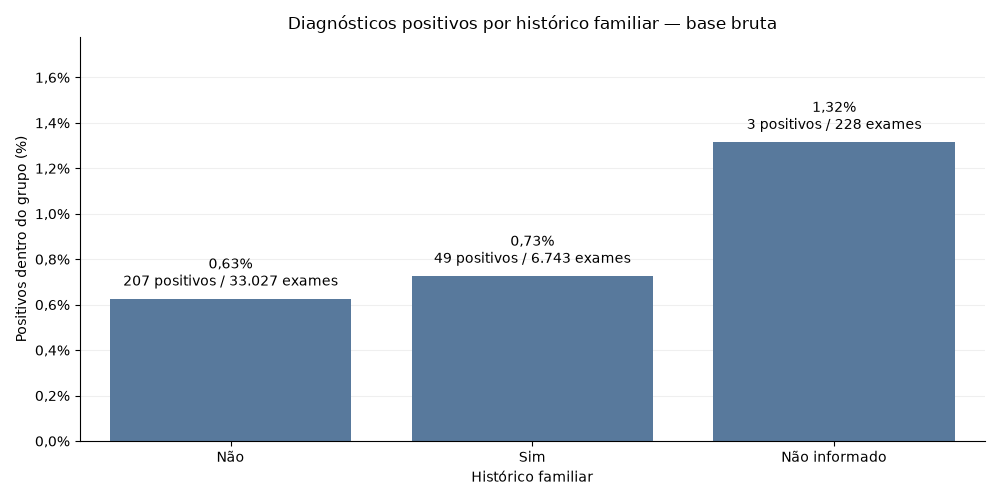

In [ ]:
# Histórico familiar na base bruta: respostas informadas e ausentes
# Mantém as ausências separadas; não altera df nem o pré-processamento.
# O percentual positivo usa o total de exames de cada grupo.
# "Não informado" tem apenas 3 positivos em 228 exames: percentual pouco estável.
from matplotlib.ticker import FuncFormatter

historico_familiar_bruto = df_bruto["Family_History_Of_Breast_Cancer"].map(
    {"No": "Não", "Yes": "Sim"}
).fillna("Não informado")

resumo_historico_familiar_bruto = (
    df_bruto.groupby(historico_familiar_bruto)["Is_Binary_Indicator_Of_Cancer_Diagnosis"]
    .agg(**{"Total de exames": "size", "Positivos": "sum"})
    .reindex(["Não", "Sim", "Não informado"])
    .rename_axis("Histórico familiar")
    .reset_index()
)
resumo_historico_familiar_bruto["Positivos (%)"] = (
    resumo_historico_familiar_bruto["Positivos"]
    / resumo_historico_familiar_bruto["Total de exames"] * 100
)

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(
    data=resumo_historico_familiar_bruto,
    x="Histórico familiar", y="Positivos (%)",
    order=["Não", "Sim", "Não informado"],
    color="#4C78A8", errorbar=None, ax=ax,
)
rotulos_historico_familiar_bruto = [
    f"{percentual:.2f}%".replace(".", ",")
    + f"\n{int(positivos):,} positivos / {int(total):,} exames".replace(",", ".")
    for percentual, positivos, total in zip(
        resumo_historico_familiar_bruto["Positivos (%)"],
        resumo_historico_familiar_bruto["Positivos"],
        resumo_historico_familiar_bruto["Total de exames"],
    )
]
ax.bar_label(ax.containers[0], labels=rotulos_historico_familiar_bruto, padding=6)
ax.set_title("Diagnósticos positivos por histórico familiar — base bruta")
ax.set_xlabel("Histórico familiar")
ax.set_ylabel("Positivos dentro do grupo (%)")
ax.set_ylim(0, resumo_historico_familiar_bruto["Positivos (%)"].max() * 1.35)
ax.yaxis.set_major_formatter(FuncFormatter(lambda valor, posicao: f"{valor:.1f}%".replace(".", ",")))
ax.set_axisbelow(True)
ax.yaxis.grid(True, alpha=0.2)
sns.despine(ax=ax)
fig.tight_layout()
plt.show()


In [ ]:
# Biópsia anterior x diagnóstico
# Indica se a mulher já havia feito biópsia de mama, não o resultado da biópsia.
# No pré-processamento, 815 valores ausentes foram preenchidos com "Não".
alvo = "Is_Binary_Indicator_Of_Cancer_Diagnosis"
coluna_biopsia_anterior = "History_Of_Breast_Biopsy"
categorias_biopsia_anterior = {0: "Não", 1: "Sim"}

linhas_biopsia_anterior = []

for codigo, categoria in categorias_biopsia_anterior.items():
    exames = df.loc[df[coluna_biopsia_anterior] == codigo]
    total = len(exames)
    negativos = (exames[alvo] == 0).sum()
    positivos = (exames[alvo] == 1).sum()

    linhas_biopsia_anterior.append({
        "Biópsia anterior": categoria,
        "Total de exames": total,
        "Participação na amostra (%)": total / len(df) * 100,
        "Negativos": negativos,
        "Negativos (%)": negativos / total * 100,
        "Positivos": positivos,
        "Positivos (%)": positivos / total * 100,
    })

resumo_biopsia_anterior = pd.DataFrame(linhas_biopsia_anterior).round(2)
resumo_biopsia_anterior


Biópsia anterior,Total de exames,Participação na amostra (%),Negativos,Negativos (%),Positivos,Positivos (%)
Não,29548,73.87,29386,99.45,162,0.55
Sim,10450,26.13,10353,99.07,97,0.93


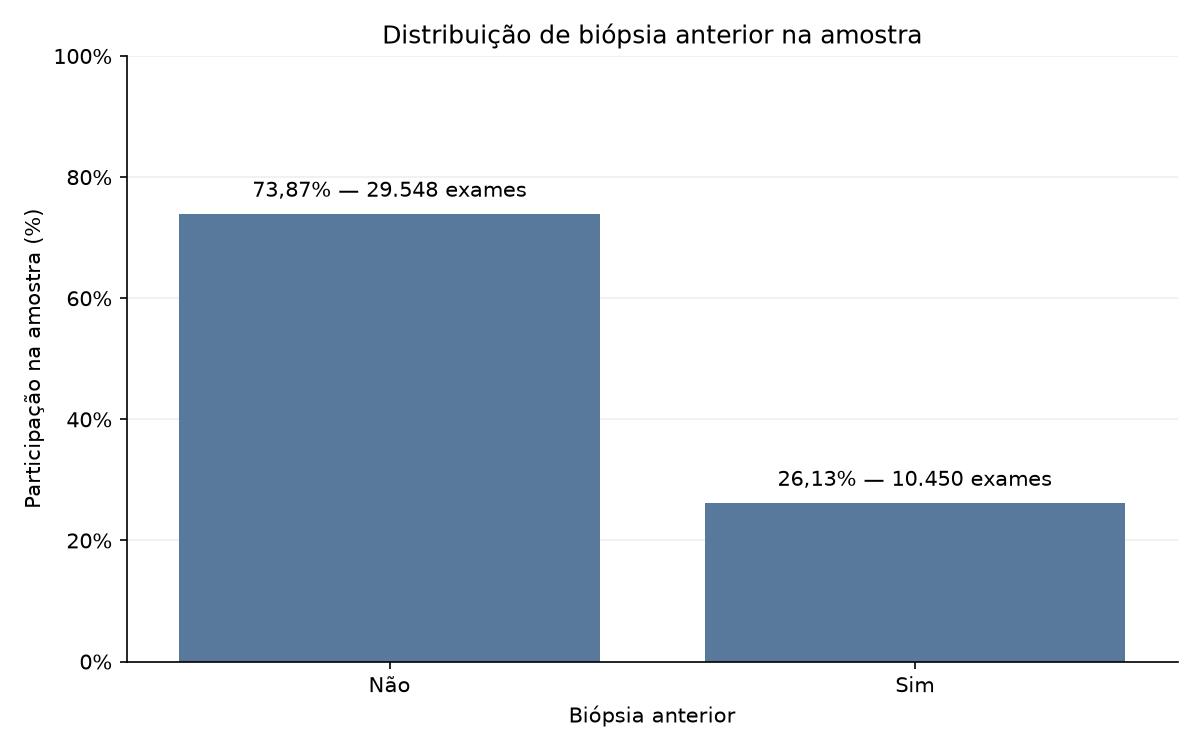

In [ ]:
# Distribuição de biópsia anterior na amostra
# Indica ter realizado biópsia de mama, não o resultado dela.
# O percentual usa todos os exames, independentemente do diagnóstico.
# O grupo "Não" inclui 815 respostas ausentes preenchidas no pré-processamento.
from matplotlib.ticker import FuncFormatter

fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(
    data=resumo_biopsia_anterior,
    x="Biópsia anterior",
    y="Participação na amostra (%)",
    order=resumo_biopsia_anterior["Biópsia anterior"].tolist(),
    color="#4C78A8",
    errorbar=None,
    ax=ax,
)

rotulos_distribuicao_biopsia_anterior = []
for percentual, quantidade in zip(
    resumo_biopsia_anterior["Participação na amostra (%)"],
    resumo_biopsia_anterior["Total de exames"],
):
    percentual_formatado = f"{percentual:.2f}".replace(".", ",")
    quantidade_formatada = f"{quantidade:,}".replace(",", ".")
    rotulos_distribuicao_biopsia_anterior.append(
        f"{percentual_formatado}% — {quantidade_formatada} exames"
    )

ax.bar_label(ax.containers[0], labels=rotulos_distribuicao_biopsia_anterior, padding=6)
ax.set_title("Distribuição de biópsia anterior na amostra")
ax.set_xlabel("Biópsia anterior")
ax.set_ylabel("Participação na amostra (%)")
ax.set_ylim(0, 100)
ax.yaxis.set_major_formatter(
    FuncFormatter(lambda valor, posicao: f"{valor:.0f}%")
)
ax.set_axisbelow(True)
ax.yaxis.grid(True, alpha=0.2)
sns.despine(ax=ax)
fig.tight_layout()
plt.show()


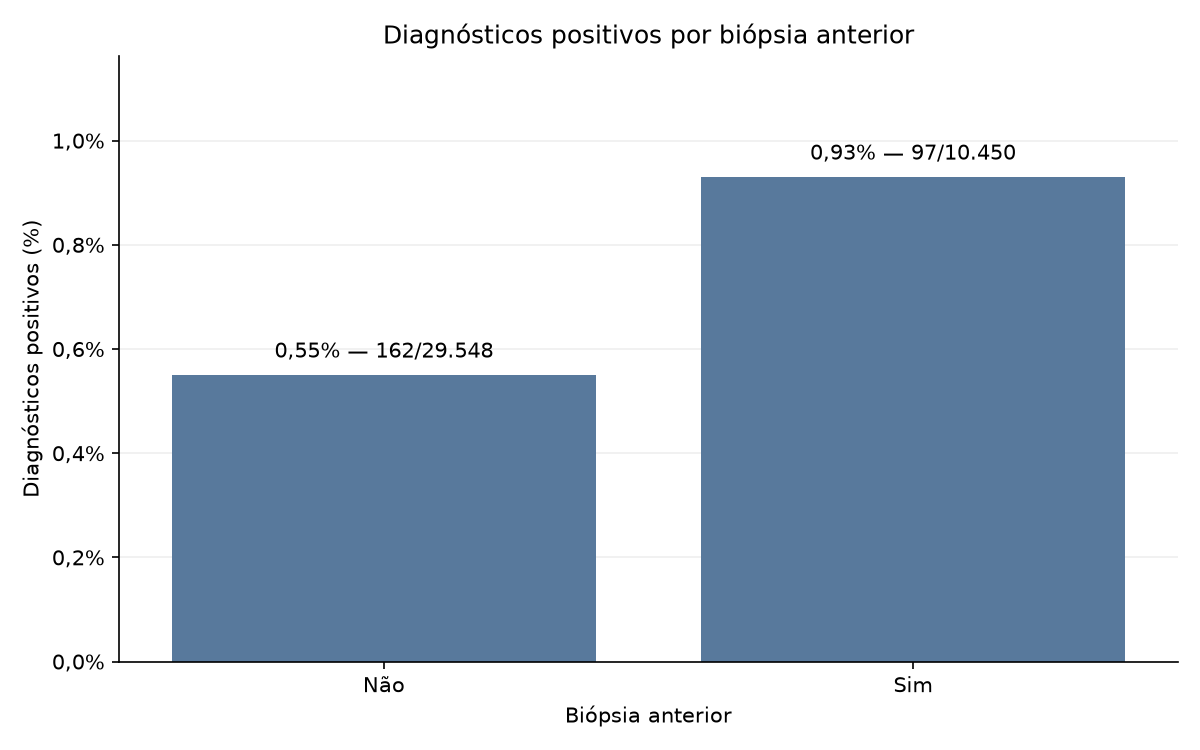

In [ ]:
# Percentual de diagnósticos positivos por biópsia anterior
# A variável indica ter realizado biópsia, não o resultado dela.
# O grupo "Não" inclui 815 respostas ausentes preenchidas no pré-processamento.
from matplotlib.ticker import FuncFormatter

fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(
    data=resumo_biopsia_anterior,
    x="Biópsia anterior",
    y="Positivos (%)",
    order=resumo_biopsia_anterior["Biópsia anterior"].tolist(),
    color="#4C78A8",
    errorbar=None,
    ax=ax,
)

rotulos_positivos_biopsia_anterior = []
for percentual, positivos, total in zip(
    resumo_biopsia_anterior["Positivos (%)"],
    resumo_biopsia_anterior["Positivos"],
    resumo_biopsia_anterior["Total de exames"],
):
    percentual_formatado = f"{percentual:.2f}".replace(".", ",")
    positivos_formatados = f"{positivos:,}".replace(",", ".")
    total_formatado = f"{total:,}".replace(",", ".")
    rotulos_positivos_biopsia_anterior.append(
        f"{percentual_formatado}% — {positivos_formatados}/{total_formatado}"
    )

ax.bar_label(ax.containers[0], labels=rotulos_positivos_biopsia_anterior, padding=6)
ax.set_title("Diagnósticos positivos por biópsia anterior")
ax.set_xlabel("Biópsia anterior")
ax.set_ylabel("Diagnósticos positivos (%)")
ax.set_ylim(0, resumo_biopsia_anterior["Positivos (%)"].max() * 1.25)
ax.yaxis.set_major_formatter(
    FuncFormatter(lambda valor, posicao: f"{valor:.1f}%".replace(".", ","))
)
ax.set_axisbelow(True)
ax.yaxis.grid(True, alpha=0.2)
sns.despine(ax=ax)
fig.tight_layout()
plt.show()


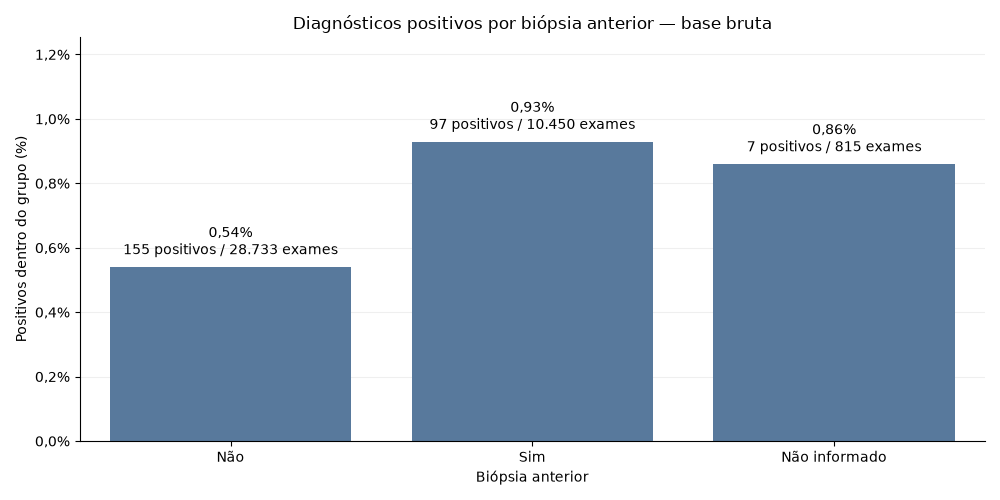

In [ ]:
# Biópsia anterior na base bruta: respostas informadas e ausentes
# Mantém as ausências separadas; não altera df nem o pré-processamento.
# O percentual positivo usa o total de exames de cada grupo.
# Indica ter realizado biópsia de mama, não o resultado dela.
# "Não informado" tem apenas 7 positivos em 815 exames: percentual pouco estável.
from matplotlib.ticker import FuncFormatter

biopsia_anterior_bruto = df_bruto["History_Of_Breast_Biopsy"].map(
    {"No": "Não", "Yes": "Sim"}
).fillna("Não informado")

resumo_biopsia_anterior_bruto = (
    df_bruto.groupby(biopsia_anterior_bruto)["Is_Binary_Indicator_Of_Cancer_Diagnosis"]
    .agg(**{"Total de exames": "size", "Positivos": "sum"})
    .reindex(["Não", "Sim", "Não informado"])
    .rename_axis("Biópsia anterior")
    .reset_index()
)
resumo_biopsia_anterior_bruto["Positivos (%)"] = (
    resumo_biopsia_anterior_bruto["Positivos"]
    / resumo_biopsia_anterior_bruto["Total de exames"] * 100
)

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(
    data=resumo_biopsia_anterior_bruto,
    x="Biópsia anterior", y="Positivos (%)",
    order=["Não", "Sim", "Não informado"],
    color="#4C78A8", errorbar=None, ax=ax,
)
rotulos_biopsia_anterior_bruto = [
    f"{percentual:.2f}%".replace(".", ",")
    + f"\n{int(positivos):,} positivos / {int(total):,} exames".replace(",", ".")
    for percentual, positivos, total in zip(
        resumo_biopsia_anterior_bruto["Positivos (%)"],
        resumo_biopsia_anterior_bruto["Positivos"],
        resumo_biopsia_anterior_bruto["Total de exames"],
    )
]
ax.bar_label(ax.containers[0], labels=rotulos_biopsia_anterior_bruto, padding=6)
ax.set_title("Diagnósticos positivos por biópsia anterior — base bruta")
ax.set_xlabel("Biópsia anterior")
ax.set_ylabel("Positivos dentro do grupo (%)")
ax.set_ylim(0, resumo_biopsia_anterior_bruto["Positivos (%)"].max() * 1.35)
ax.yaxis.set_major_formatter(FuncFormatter(lambda valor, posicao: f"{valor:.1f}%".replace(".", ",")))
ax.set_axisbelow(True)
ax.yaxis.grid(True, alpha=0.2)
sns.despine(ax=ax)
fig.tight_layout()
plt.show()


In [ ]:
# Terapia hormonal x diagnóstico
# No pré-processamento, 1.772 valores ausentes foram preenchidos com "Não".
alvo = "Is_Binary_Indicator_Of_Cancer_Diagnosis"
coluna_terapia_hormonal = "Current_Use_Of_Hormone_Therapy"
categorias_terapia_hormonal = {0: "Não", 1: "Sim"}

linhas_terapia_hormonal = []

for codigo, categoria in categorias_terapia_hormonal.items():
    exames = df.loc[df[coluna_terapia_hormonal] == codigo]
    total = len(exames)
    negativos = (exames[alvo] == 0).sum()
    positivos = (exames[alvo] == 1).sum()

    linhas_terapia_hormonal.append({
        "Terapia hormonal": categoria,
        "Total de exames": total,
        "Participação na amostra (%)": total / len(df) * 100,
        "Negativos": negativos,
        "Negativos (%)": negativos / total * 100,
        "Positivos": positivos,
        "Positivos (%)": positivos / total * 100,
    })

resumo_terapia_hormonal = pd.DataFrame(linhas_terapia_hormonal).round(2)
resumo_terapia_hormonal


Terapia hormonal,Total de exames,Participação na amostra (%),Negativos,Negativos (%),Positivos,Positivos (%)
Não,35749,89.38,35519,99.36,230,0.64
Sim,4249,10.62,4220,99.32,29,0.68


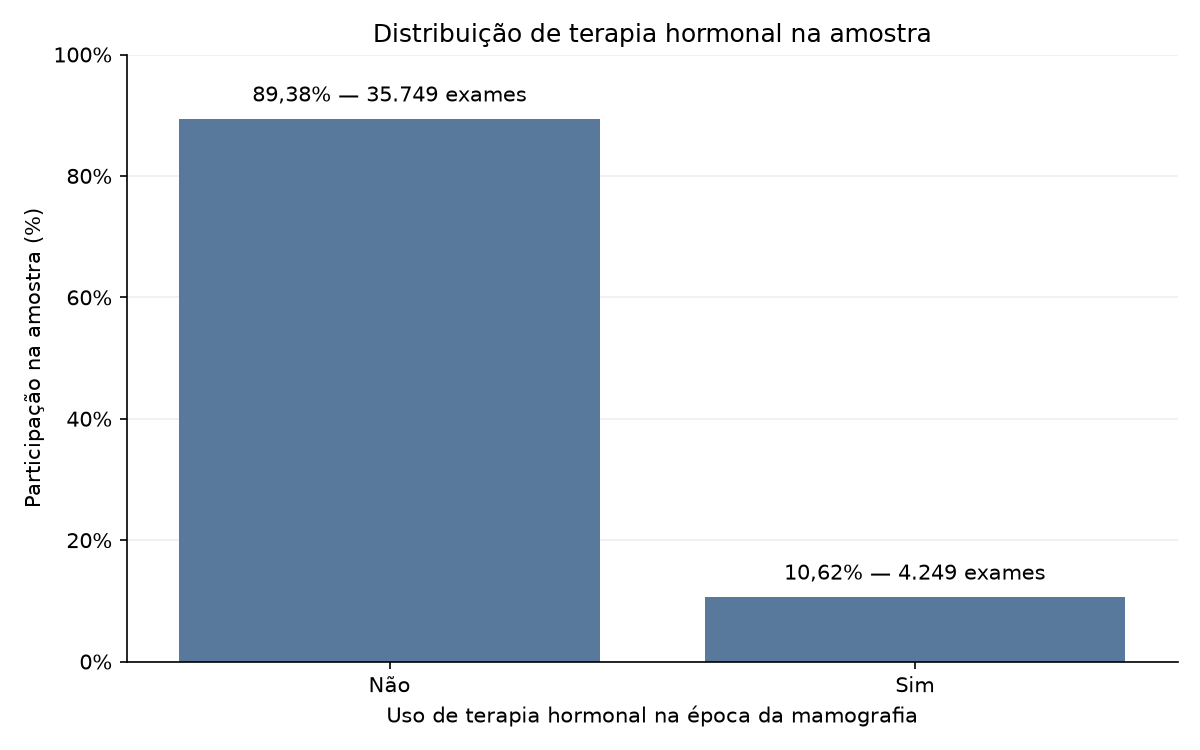

In [ ]:
# Distribuição de terapia hormonal na amostra
# A variável registra o uso de terapia hormonal na época da mamografia.
# O percentual usa todos os exames, independentemente do diagnóstico.
# O grupo "Não" inclui 1.772 respostas ausentes preenchidas no pré-processamento.
from matplotlib.ticker import FuncFormatter

fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(
    data=resumo_terapia_hormonal,
    x="Terapia hormonal",
    y="Participação na amostra (%)",
    order=resumo_terapia_hormonal["Terapia hormonal"].tolist(),
    color="#4C78A8",
    errorbar=None,
    ax=ax,
)

rotulos_distribuicao_terapia_hormonal = []
for percentual, quantidade in zip(
    resumo_terapia_hormonal["Participação na amostra (%)"],
    resumo_terapia_hormonal["Total de exames"],
):
    percentual_formatado = f"{percentual:.2f}".replace(".", ",")
    quantidade_formatada = f"{quantidade:,}".replace(",", ".")
    rotulos_distribuicao_terapia_hormonal.append(
        f"{percentual_formatado}% — {quantidade_formatada} exames"
    )

ax.bar_label(ax.containers[0], labels=rotulos_distribuicao_terapia_hormonal, padding=6)
ax.set_title("Distribuição de terapia hormonal na amostra")
ax.set_xlabel("Uso de terapia hormonal na época da mamografia")
ax.set_ylabel("Participação na amostra (%)")
ax.set_ylim(0, 100)
ax.yaxis.set_major_formatter(
    FuncFormatter(lambda valor, posicao: f"{valor:.0f}%")
)
ax.set_axisbelow(True)
ax.yaxis.grid(True, alpha=0.2)
sns.despine(ax=ax)
fig.tight_layout()
plt.show()


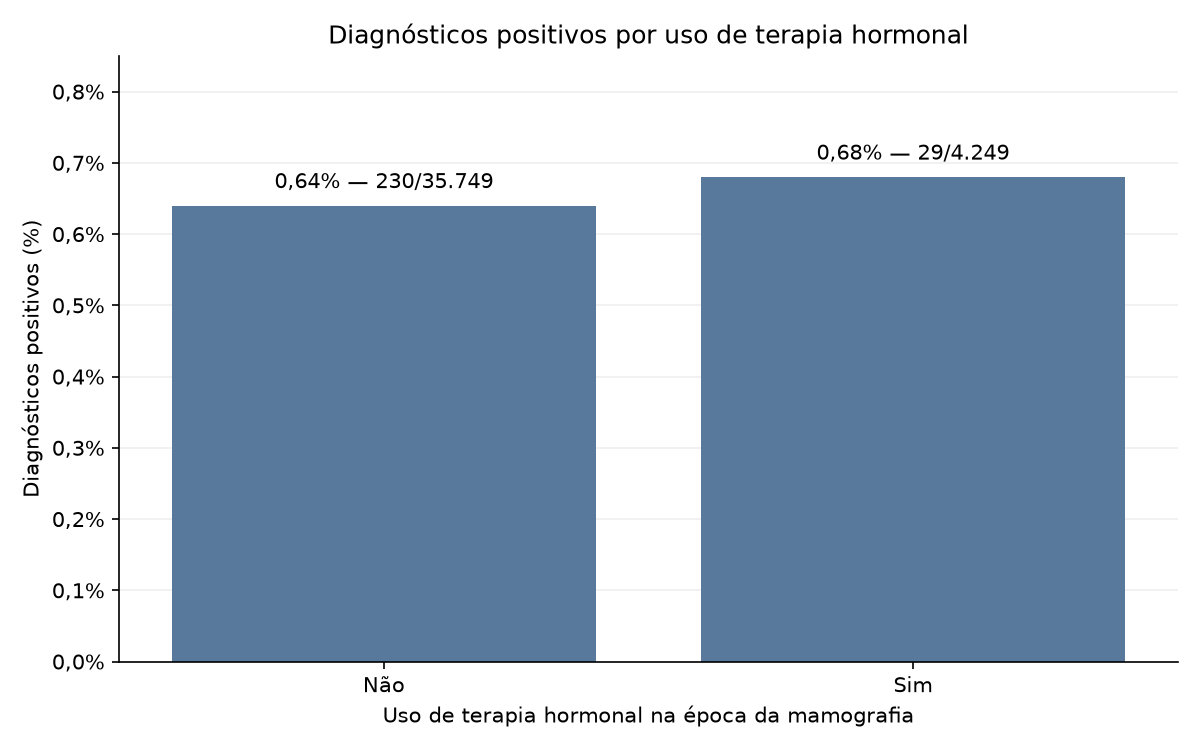

In [ ]:
# Percentual de diagnósticos positivos por uso de terapia hormonal
# A variável registra o uso de terapia hormonal na época da mamografia.
# O grupo "Não" inclui 1.772 respostas ausentes preenchidas no pré-processamento.
from matplotlib.ticker import FuncFormatter

fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(
    data=resumo_terapia_hormonal,
    x="Terapia hormonal",
    y="Positivos (%)",
    order=resumo_terapia_hormonal["Terapia hormonal"].tolist(),
    color="#4C78A8",
    errorbar=None,
    ax=ax,
)

rotulos_positivos_terapia_hormonal = []
for percentual, positivos, total in zip(
    resumo_terapia_hormonal["Positivos (%)"],
    resumo_terapia_hormonal["Positivos"],
    resumo_terapia_hormonal["Total de exames"],
):
    percentual_formatado = f"{percentual:.2f}".replace(".", ",")
    positivos_formatados = f"{positivos:,}".replace(",", ".")
    total_formatado = f"{total:,}".replace(",", ".")
    rotulos_positivos_terapia_hormonal.append(
        f"{percentual_formatado}% — {positivos_formatados}/{total_formatado}"
    )

ax.bar_label(ax.containers[0], labels=rotulos_positivos_terapia_hormonal, padding=6)
ax.set_title("Diagnósticos positivos por uso de terapia hormonal")
ax.set_xlabel("Uso de terapia hormonal na época da mamografia")
ax.set_ylabel("Diagnósticos positivos (%)")
ax.set_ylim(0, resumo_terapia_hormonal["Positivos (%)"].max() * 1.25)
ax.yaxis.set_major_formatter(
    FuncFormatter(lambda valor, posicao: f"{valor:.1f}%".replace(".", ","))
)
ax.set_axisbelow(True)
ax.yaxis.grid(True, alpha=0.2)
sns.despine(ax=ax)
fig.tight_layout()
plt.show()


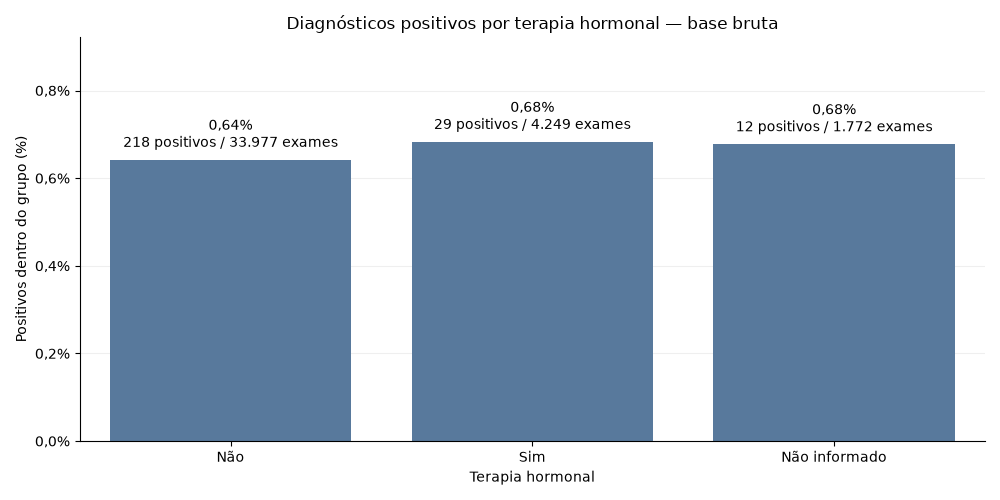

In [ ]:
# Terapia hormonal na base bruta: respostas informadas e ausentes
# Mantém as ausências separadas; não altera df nem o pré-processamento.
# O percentual positivo usa o total de exames de cada grupo.
# Indica uso de terapia hormonal na época da mamografia.
# "Não informado" reúne 12 positivos em 1.772 exames.
from matplotlib.ticker import FuncFormatter

terapia_hormonal_bruto = df_bruto["Current_Use_Of_Hormone_Therapy"].map(
    {"No": "Não", "Yes": "Sim"}
).fillna("Não informado")

resumo_terapia_hormonal_bruto = (
    df_bruto.groupby(terapia_hormonal_bruto)["Is_Binary_Indicator_Of_Cancer_Diagnosis"]
    .agg(**{"Total de exames": "size", "Positivos": "sum"})
    .reindex(["Não", "Sim", "Não informado"])
    .rename_axis("Terapia hormonal")
    .reset_index()
)
resumo_terapia_hormonal_bruto["Positivos (%)"] = (
    resumo_terapia_hormonal_bruto["Positivos"]
    / resumo_terapia_hormonal_bruto["Total de exames"] * 100
)

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(
    data=resumo_terapia_hormonal_bruto,
    x="Terapia hormonal", y="Positivos (%)",
    order=["Não", "Sim", "Não informado"],
    color="#4C78A8", errorbar=None, ax=ax,
)
rotulos_terapia_hormonal_bruto = [
    f"{percentual:.2f}%".replace(".", ",")
    + f"\n{int(positivos):,} positivos / {int(total):,} exames".replace(",", ".")
    for percentual, positivos, total in zip(
        resumo_terapia_hormonal_bruto["Positivos (%)"],
        resumo_terapia_hormonal_bruto["Positivos"],
        resumo_terapia_hormonal_bruto["Total de exames"],
    )
]
ax.bar_label(ax.containers[0], labels=rotulos_terapia_hormonal_bruto, padding=6)
ax.set_title("Diagnósticos positivos por terapia hormonal — base bruta")
ax.set_xlabel("Terapia hormonal")
ax.set_ylabel("Positivos dentro do grupo (%)")
ax.set_ylim(0, resumo_terapia_hormonal_bruto["Positivos (%)"].max() * 1.35)
ax.yaxis.set_major_formatter(FuncFormatter(lambda valor, posicao: f"{valor:.1f}%".replace(".", ",")))
ax.set_axisbelow(True)
ax.yaxis.grid(True, alpha=0.2)
sns.despine(ax=ax)
fig.tight_layout()
plt.show()


In [ ]:
# Filme x digital — diagnóstico
alvo = "Is_Binary_Indicator_Of_Cancer_Diagnosis"
coluna_tipo_mamografia = "Is_Film_Or_Digital_Mammogram"
categorias_tipo_mamografia = {0: "Filme", 1: "Digital"}

linhas_tipo_mamografia = []

for codigo, categoria in categorias_tipo_mamografia.items():
    exames = df.loc[df[coluna_tipo_mamografia] == codigo]
    total = len(exames)
    negativos = (exames[alvo] == 0).sum()
    positivos = (exames[alvo] == 1).sum()

    linhas_tipo_mamografia.append({
        "Tipo de mamografia": categoria,
        "Total de exames": total,
        "Participação na amostra (%)": total / len(df) * 100,
        "Negativos": negativos,
        "Negativos (%)": negativos / total * 100,
        "Positivos": positivos,
        "Positivos (%)": positivos / total * 100,
    })

resumo_tipo_mamografia = pd.DataFrame(linhas_tipo_mamografia).round(2)
resumo_tipo_mamografia


Tipo de mamografia,Total de exames,Participação na amostra (%),Negativos,Negativos (%),Positivos,Positivos (%)
Filme,19998,50.0,19861,99.31,137,0.69
Digital,20000,50.0,19878,99.39,122,0.61


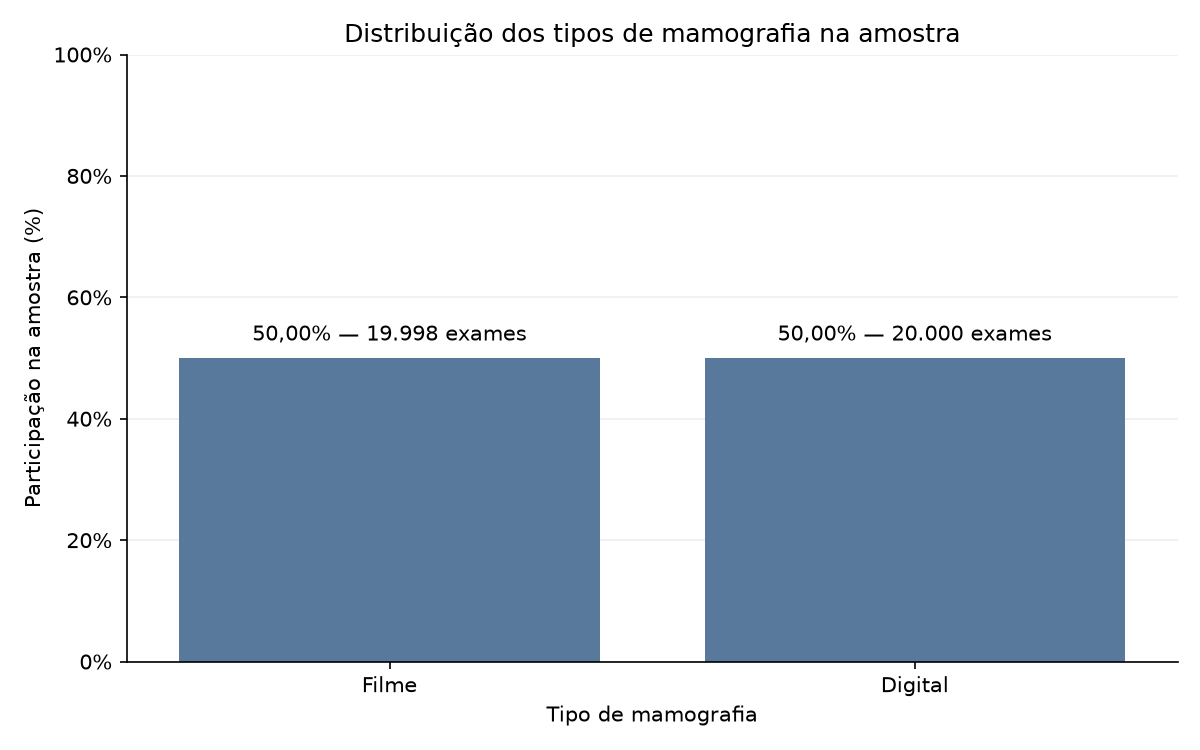

In [ ]:
# Distribuição dos tipos de mamografia na amostra
# O percentual usa todos os exames, independentemente do diagnóstico.
# Os percentuais arredondados são iguais, mas Digital tem dois exames a mais que Filme.
from matplotlib.ticker import FuncFormatter

fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(
    data=resumo_tipo_mamografia,
    x="Tipo de mamografia",
    y="Participação na amostra (%)",
    order=resumo_tipo_mamografia["Tipo de mamografia"].tolist(),
    color="#4C78A8",
    errorbar=None,
    ax=ax,
)

rotulos_distribuicao_tipo_mamografia = []
for percentual, quantidade in zip(
    resumo_tipo_mamografia["Participação na amostra (%)"],
    resumo_tipo_mamografia["Total de exames"],
):
    percentual_formatado = f"{percentual:.2f}".replace(".", ",")
    quantidade_formatada = f"{quantidade:,}".replace(",", ".")
    rotulos_distribuicao_tipo_mamografia.append(
        f"{percentual_formatado}% — {quantidade_formatada} exames"
    )

ax.bar_label(ax.containers[0], labels=rotulos_distribuicao_tipo_mamografia, padding=6)
ax.set_title("Distribuição dos tipos de mamografia na amostra")
ax.set_xlabel("Tipo de mamografia")
ax.set_ylabel("Participação na amostra (%)")
ax.set_ylim(0, 100)
ax.yaxis.set_major_formatter(
    FuncFormatter(lambda valor, posicao: f"{valor:.0f}%")
)
ax.set_axisbelow(True)
ax.yaxis.grid(True, alpha=0.2)
sns.despine(ax=ax)
fig.tight_layout()
plt.show()


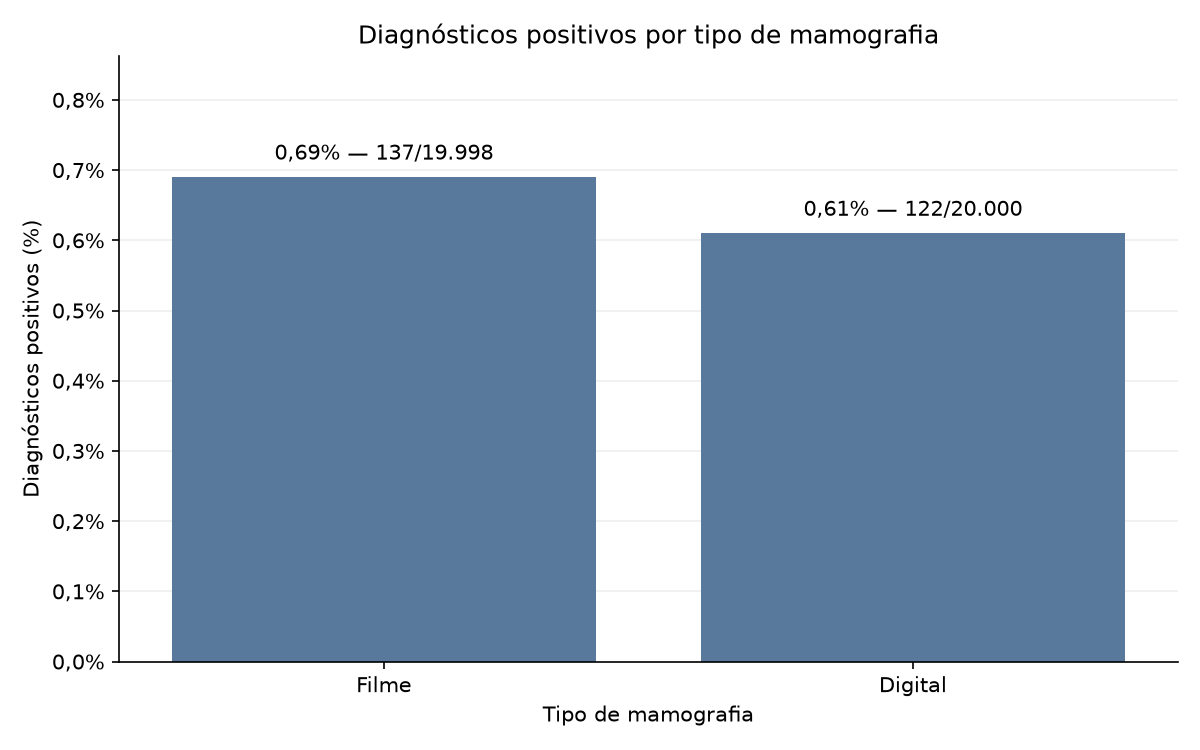

In [ ]:
# Percentual de diagnósticos positivos por tipo de mamografia
# Compara a frequência de diagnóstico nos grupos, não a capacidade de detecção das tecnologias.
from matplotlib.ticker import FuncFormatter

fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(
    data=resumo_tipo_mamografia,
    x="Tipo de mamografia",
    y="Positivos (%)",
    order=resumo_tipo_mamografia["Tipo de mamografia"].tolist(),
    color="#4C78A8",
    errorbar=None,
    ax=ax,
)

rotulos_positivos_tipo_mamografia = []
for percentual, positivos, total in zip(
    resumo_tipo_mamografia["Positivos (%)"],
    resumo_tipo_mamografia["Positivos"],
    resumo_tipo_mamografia["Total de exames"],
):
    percentual_formatado = f"{percentual:.2f}".replace(".", ",")
    positivos_formatados = f"{positivos:,}".replace(",", ".")
    total_formatado = f"{total:,}".replace(",", ".")
    rotulos_positivos_tipo_mamografia.append(
        f"{percentual_formatado}% — {positivos_formatados}/{total_formatado}"
    )

ax.bar_label(ax.containers[0], labels=rotulos_positivos_tipo_mamografia, padding=6)
ax.set_title("Diagnósticos positivos por tipo de mamografia")
ax.set_xlabel("Tipo de mamografia")
ax.set_ylabel("Diagnósticos positivos (%)")
ax.set_ylim(0, resumo_tipo_mamografia["Positivos (%)"].max() * 1.25)
ax.yaxis.set_major_formatter(
    FuncFormatter(lambda valor, posicao: f"{valor:.1f}%".replace(".", ","))
)
ax.set_axisbelow(True)
ax.yaxis.grid(True, alpha=0.2)
sns.despine(ax=ax)
fig.tight_layout()
plt.show()


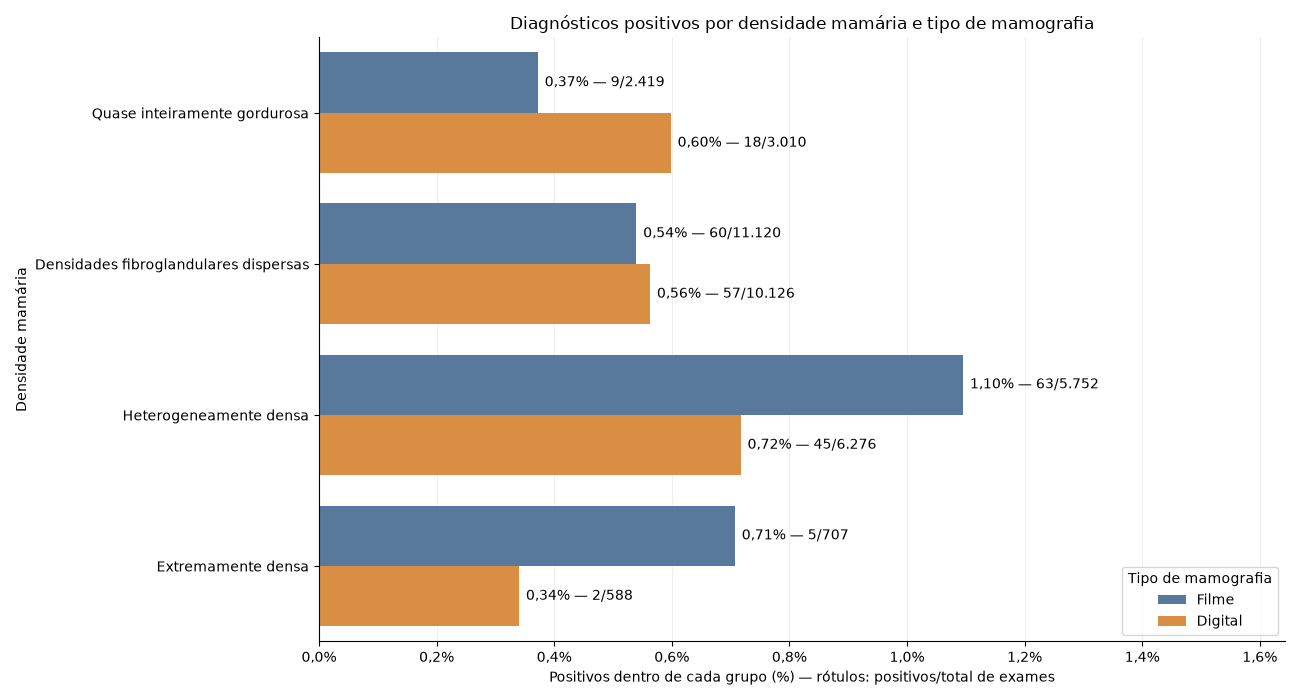

In [ ]:
# Diagnósticos positivos por densidade mamária e tipo de mamografia
# O denominador é o total de exames de cada combinação de densidade e tipo.
# Esta comparação descritiva não mede diretamente a capacidade de detecção.
from matplotlib.ticker import FuncFormatter

dados_densidade_tipo = df.assign(**{
    "Densidade mamária": df["Patients_BI_RADS_Breast_Density"].map(categorias_densidade),
    "Tipo de mamografia": df["Is_Film_Or_Digital_Mammogram"].map(categorias_tipo_mamografia),
})
resumo_densidade_tipo = (
    dados_densidade_tipo.groupby(["Densidade mamária", "Tipo de mamografia"])
    ["Is_Binary_Indicator_Of_Cancer_Diagnosis"]
    .agg(**{"Total de exames": "size", "Positivos": "sum"})
    .reset_index()
)
resumo_densidade_tipo["Positivos (%)"] = (
    resumo_densidade_tipo["Positivos"] / resumo_densidade_tipo["Total de exames"] * 100
)
ordem_densidade_tipo = list(categorias_densidade.values())
ordem_tipos = ["Filme", "Digital"]

fig, ax = plt.subplots(figsize=(13, 7))
sns.barplot(
    data=resumo_densidade_tipo,
    x="Positivos (%)", y="Densidade mamária", hue="Tipo de mamografia",
    order=ordem_densidade_tipo, hue_order=ordem_tipos,
    palette={"Filme": "#4C78A8", "Digital": "#F28E2B"},
    errorbar=None, orient="h", ax=ax,
)
for barras, tipo in zip(ax.containers, ordem_tipos):
    grupos = (
        resumo_densidade_tipo.loc[resumo_densidade_tipo["Tipo de mamografia"] == tipo]
        .set_index("Densidade mamária").reindex(ordem_densidade_tipo)
    )
    rotulos = [
        f"{percentual:.2f}%".replace(".", ",")
        + f" — {int(positivos):,}/{int(total):,}".replace(",", ".")
        for percentual, positivos, total in zip(
            grupos["Positivos (%)"], grupos["Positivos"], grupos["Total de exames"]
        )
    ]
    ax.bar_label(barras, labels=rotulos, padding=5)
ax.set_title("Diagnósticos positivos por densidade mamária e tipo de mamografia")
ax.set_xlabel("Positivos dentro de cada grupo (%) — rótulos: positivos/total de exames")
ax.set_ylabel("Densidade mamária")
ax.set_xlim(0, resumo_densidade_tipo["Positivos (%)"].max() * 1.5)
ax.xaxis.set_major_formatter(FuncFormatter(lambda valor, posicao: f"{valor:.1f}%".replace(".", ",")))
ax.legend(title="Tipo de mamografia", loc="lower right")
ax.set_axisbelow(True)
ax.xaxis.grid(True, alpha=0.2)
sns.despine(ax=ax)
fig.tight_layout()
plt.show()


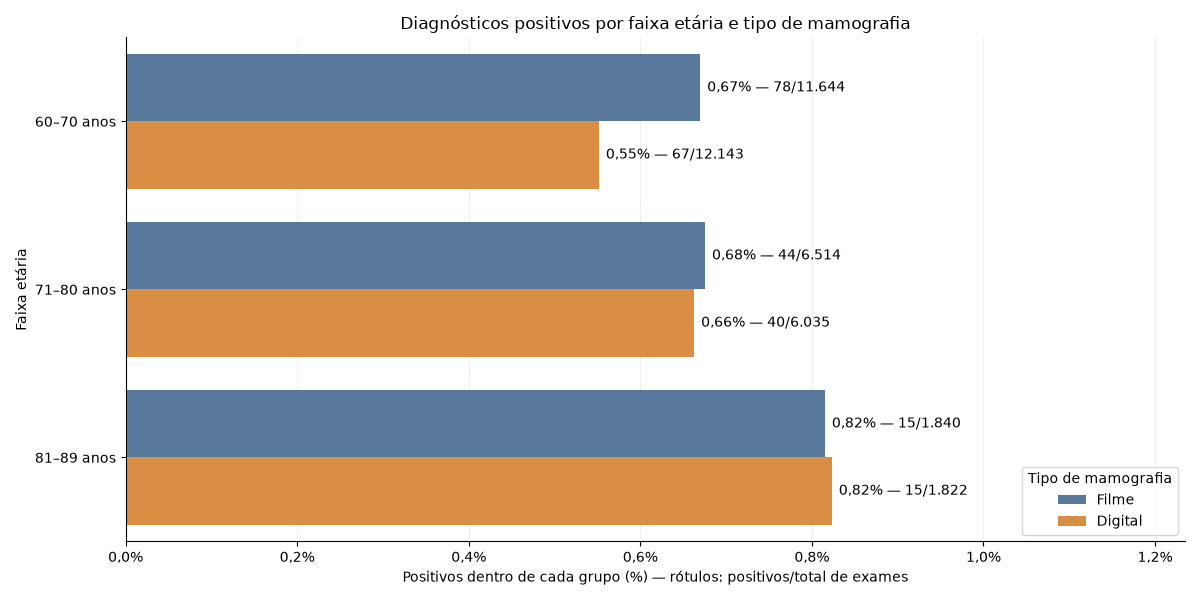

In [ ]:
# Diagnósticos positivos por faixa etária e tipo de mamografia
# O denominador é o total de exames de cada combinação de faixa etária e tipo.
# Esta comparação descritiva não mede diretamente a capacidade de detecção.
from matplotlib.ticker import FuncFormatter

dados_idade_tipo = df.assign(**{
    "Faixa etária": pd.cut(
        df["Age_At_The_Time_Of_Mammography"], bins=[59, 70, 80, 89],
        labels=["60–70 anos", "71–80 anos", "81–89 anos"],
    ),
    "Tipo de mamografia": df["Is_Film_Or_Digital_Mammogram"].map(categorias_tipo_mamografia),
})
resumo_idade_tipo = (
    dados_idade_tipo.groupby(["Faixa etária", "Tipo de mamografia"], observed=True)
    ["Is_Binary_Indicator_Of_Cancer_Diagnosis"]
    .agg(**{"Total de exames": "size", "Positivos": "sum"})
    .reset_index()
)
resumo_idade_tipo["Positivos (%)"] = (
    resumo_idade_tipo["Positivos"] / resumo_idade_tipo["Total de exames"] * 100
)
ordem_idade_tipo = ["60–70 anos", "71–80 anos", "81–89 anos"]
ordem_tipos = ["Filme", "Digital"]

fig, ax = plt.subplots(figsize=(12, 6))
sns.barplot(
    data=resumo_idade_tipo,
    x="Positivos (%)", y="Faixa etária", hue="Tipo de mamografia",
    order=ordem_idade_tipo, hue_order=ordem_tipos,
    palette={"Filme": "#4C78A8", "Digital": "#F28E2B"},
    errorbar=None, orient="h", ax=ax,
)
for barras, tipo in zip(ax.containers, ordem_tipos):
    grupos = (
        resumo_idade_tipo.loc[resumo_idade_tipo["Tipo de mamografia"] == tipo]
        .set_index("Faixa etária").reindex(ordem_idade_tipo)
    )
    rotulos = [
        f"{percentual:.2f}%".replace(".", ",")
        + f" — {int(positivos):,}/{int(total):,}".replace(",", ".")
        for percentual, positivos, total in zip(
            grupos["Positivos (%)"], grupos["Positivos"], grupos["Total de exames"]
        )
    ]
    ax.bar_label(barras, labels=rotulos, padding=5)
ax.set_title("Diagnósticos positivos por faixa etária e tipo de mamografia")
ax.set_xlabel("Positivos dentro de cada grupo (%) — rótulos: positivos/total de exames")
ax.set_ylabel("Faixa etária")
ax.set_xlim(0, resumo_idade_tipo["Positivos (%)"].max() * 1.5)
ax.xaxis.set_major_formatter(FuncFormatter(lambda valor, posicao: f"{valor:.1f}%".replace(".", ",")))
ax.legend(title="Tipo de mamografia", loc="lower right")
ax.set_axisbelow(True)
ax.xaxis.grid(True, alpha=0.2)
sns.despine(ax=ax)
fig.tight_layout()
plt.show()


In [ ]:
# Mamografia prévia x diagnóstico
# No pré-processamento, 578 valores ausentes foram preenchidos com "Sim".
alvo = "Is_Binary_Indicator_Of_Cancer_Diagnosis"
coluna_mamografia_previa = "Binary_Indicator"
categorias_mamografia_previa = {0: "Não", 1: "Sim"}

linhas_mamografia_previa = []

for codigo, categoria in categorias_mamografia_previa.items():
    exames = df.loc[df[coluna_mamografia_previa] == codigo]
    total = len(exames)
    negativos = (exames[alvo] == 0).sum()
    positivos = (exames[alvo] == 1).sum()

    linhas_mamografia_previa.append({
        "Mamografia prévia": categoria,
        "Total de exames": total,
        "Participação na amostra (%)": total / len(df) * 100,
        "Negativos": negativos,
        "Negativos (%)": negativos / total * 100,
        "Positivos": positivos,
        "Positivos (%)": positivos / total * 100,
    })

resumo_mamografia_previa = pd.DataFrame(linhas_mamografia_previa).round(2)
resumo_mamografia_previa


Mamografia prévia,Total de exames,Participação na amostra (%),Negativos,Negativos (%),Positivos,Positivos (%)
Não,296,0.74,292,98.65,4,1.35
Sim,39702,99.26,39447,99.36,255,0.64


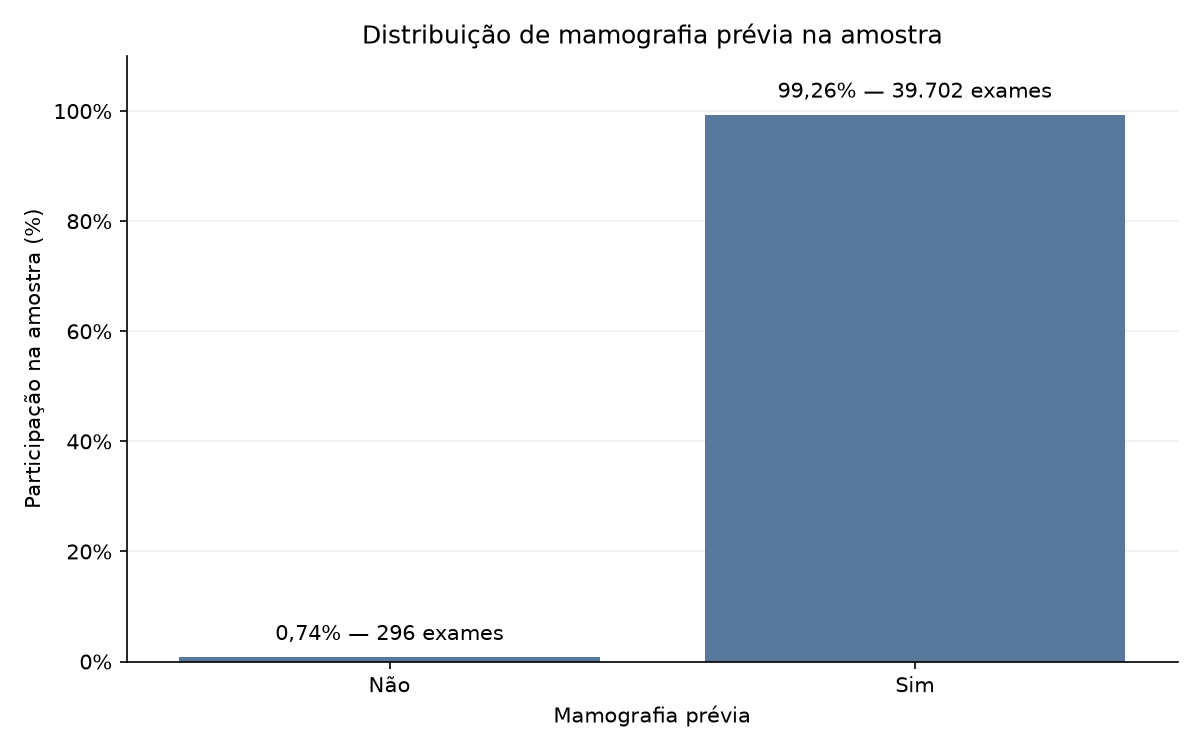

In [ ]:
# Distribuição de mamografia prévia na amostra
# O percentual usa todos os exames, independentemente do diagnóstico.
# O grupo "Sim" inclui 578 respostas ausentes preenchidas no pré-processamento.
from matplotlib.ticker import FuncFormatter

fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(
    data=resumo_mamografia_previa,
    x="Mamografia prévia",
    y="Participação na amostra (%)",
    order=resumo_mamografia_previa["Mamografia prévia"].tolist(),
    color="#4C78A8",
    errorbar=None,
    ax=ax,
)

rotulos_distribuicao_mamografia_previa = []
for percentual, quantidade in zip(
    resumo_mamografia_previa["Participação na amostra (%)"],
    resumo_mamografia_previa["Total de exames"],
):
    percentual_formatado = f"{percentual:.2f}".replace(".", ",")
    quantidade_formatada = f"{quantidade:,}".replace(",", ".")
    rotulos_distribuicao_mamografia_previa.append(
        f"{percentual_formatado}% — {quantidade_formatada} exames"
    )

ax.bar_label(ax.containers[0], labels=rotulos_distribuicao_mamografia_previa, padding=6)
ax.set_title("Distribuição de mamografia prévia na amostra")
ax.set_xlabel("Mamografia prévia")
ax.set_ylabel("Participação na amostra (%)")
ax.set_ylim(0, 110)
# A margem acima de 100% evita cortar o rótulo do grupo majoritário.
ax.yaxis.set_major_formatter(
    FuncFormatter(lambda valor, posicao: f"{valor:.0f}%")
)
ax.set_axisbelow(True)
ax.yaxis.grid(True, alpha=0.2)
sns.despine(ax=ax)
fig.tight_layout()
plt.show()


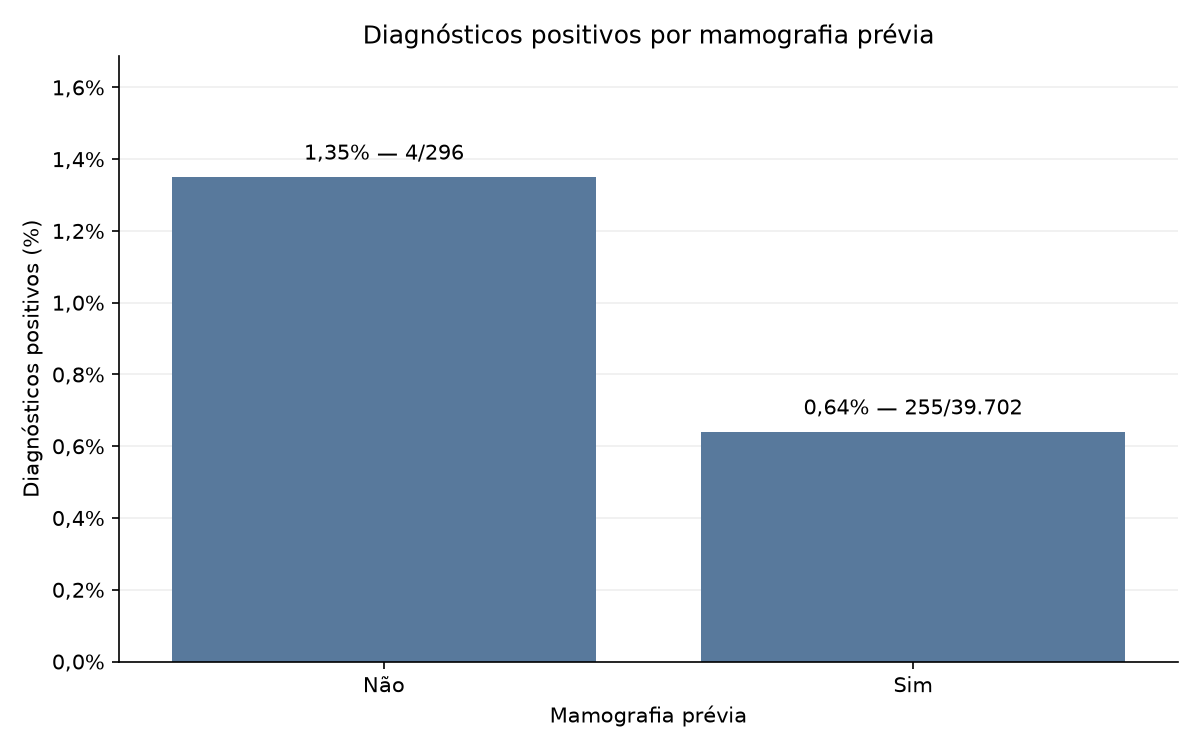

In [ ]:
# Percentual de diagnósticos positivos por mamografia prévia
# O grupo "Sim" inclui 578 respostas ausentes preenchidas no pré-processamento.
# O grupo "Não" tem apenas 4 positivos; a comparação não demonstra efeito protetor de exames anteriores.
from matplotlib.ticker import FuncFormatter

fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(
    data=resumo_mamografia_previa,
    x="Mamografia prévia",
    y="Positivos (%)",
    order=resumo_mamografia_previa["Mamografia prévia"].tolist(),
    color="#4C78A8",
    errorbar=None,
    ax=ax,
)

rotulos_positivos_mamografia_previa = []
for percentual, positivos, total in zip(
    resumo_mamografia_previa["Positivos (%)"],
    resumo_mamografia_previa["Positivos"],
    resumo_mamografia_previa["Total de exames"],
):
    percentual_formatado = f"{percentual:.2f}".replace(".", ",")
    positivos_formatados = f"{positivos:,}".replace(",", ".")
    total_formatado = f"{total:,}".replace(",", ".")
    rotulos_positivos_mamografia_previa.append(
        f"{percentual_formatado}% — {positivos_formatados}/{total_formatado}"
    )

ax.bar_label(ax.containers[0], labels=rotulos_positivos_mamografia_previa, padding=6)
ax.set_title("Diagnósticos positivos por mamografia prévia")
ax.set_xlabel("Mamografia prévia")
ax.set_ylabel("Diagnósticos positivos (%)")
ax.set_ylim(0, resumo_mamografia_previa["Positivos (%)"].max() * 1.25)
ax.yaxis.set_major_formatter(
    FuncFormatter(lambda valor, posicao: f"{valor:.1f}%".replace(".", ","))
)
ax.set_axisbelow(True)
ax.yaxis.grid(True, alpha=0.2)
sns.despine(ax=ax)
fig.tight_layout()
plt.show()


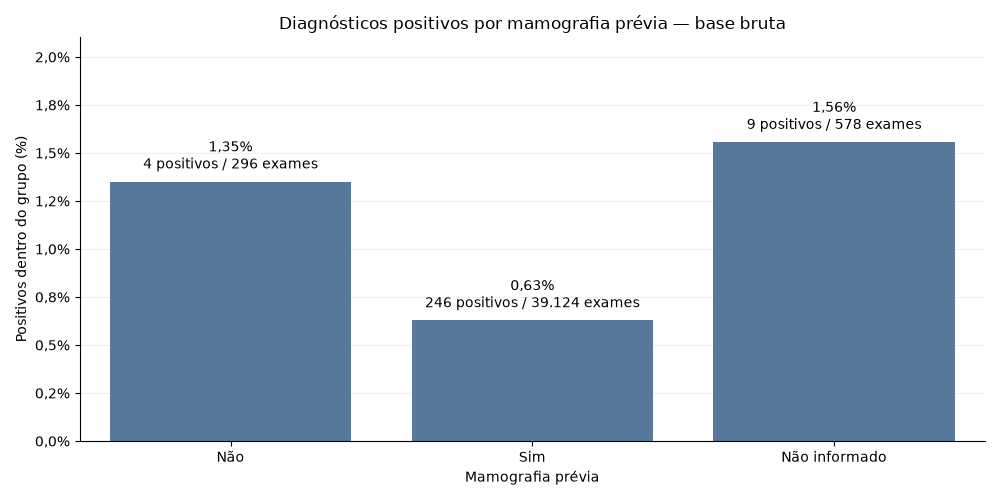

In [ ]:
# Mamografia prévia na base bruta: respostas informadas e ausentes
# Mantém as ausências separadas; não altera df nem o pré-processamento.
# O percentual positivo usa o total de exames de cada grupo.
# Indica se a mulher já havia realizado mamografia anteriormente.
# Os grupos "Não" e "Não informado" têm poucos positivos: 4 e 9, respectivamente.
from matplotlib.ticker import FuncFormatter

mamografia_previa_bruto = df_bruto["Binary_Indicator"].map(
    {"No": "Não", "Yes": "Sim"}
).fillna("Não informado")

resumo_mamografia_previa_bruto = (
    df_bruto.groupby(mamografia_previa_bruto)["Is_Binary_Indicator_Of_Cancer_Diagnosis"]
    .agg(**{"Total de exames": "size", "Positivos": "sum"})
    .reindex(["Não", "Sim", "Não informado"])
    .rename_axis("Mamografia prévia")
    .reset_index()
)
resumo_mamografia_previa_bruto["Positivos (%)"] = (
    resumo_mamografia_previa_bruto["Positivos"]
    / resumo_mamografia_previa_bruto["Total de exames"] * 100
)

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(
    data=resumo_mamografia_previa_bruto,
    x="Mamografia prévia", y="Positivos (%)",
    order=["Não", "Sim", "Não informado"],
    color="#4C78A8", errorbar=None, ax=ax,
)
rotulos_mamografia_previa_bruto = [
    f"{percentual:.2f}%".replace(".", ",")
    + f"\n{int(positivos):,} positivos / {int(total):,} exames".replace(",", ".")
    for percentual, positivos, total in zip(
        resumo_mamografia_previa_bruto["Positivos (%)"],
        resumo_mamografia_previa_bruto["Positivos"],
        resumo_mamografia_previa_bruto["Total de exames"],
    )
]
ax.bar_label(ax.containers[0], labels=rotulos_mamografia_previa_bruto, padding=6)
ax.set_title("Diagnósticos positivos por mamografia prévia — base bruta")
ax.set_xlabel("Mamografia prévia")
ax.set_ylabel("Positivos dentro do grupo (%)")
ax.set_ylim(0, resumo_mamografia_previa_bruto["Positivos (%)"].max() * 1.35)
ax.yaxis.set_major_formatter(FuncFormatter(lambda valor, posicao: f"{valor:.1f}%".replace(".", ",")))
ax.set_axisbelow(True)
ax.yaxis.grid(True, alpha=0.2)
sns.despine(ax=ax)
fig.tight_layout()
plt.show()


In [ ]:
# Disponibilidade de exame anterior x diagnóstico
# Mamografia prévia indica se a mulher já fez o exame alguma vez.
# Esta variável indica se as imagens de um exame anterior estavam disponíveis
# para o radiologista comparar com as atuais. Ela pode ter feito uma mamografia
# em outra clínica, por exemplo, sem que as imagens estivessem disponíveis aqui.
# No pré-processamento, 4.680 valores ausentes foram preenchidos com "Sim".
alvo = "Is_Binary_Indicator_Of_Cancer_Diagnosis"
coluna_exame_anterior = "Comparison_Mammogram_From_Mammography"
categorias_exame_anterior = {0: "Não", 1: "Sim"}

linhas_exame_anterior = []

for codigo, categoria in categorias_exame_anterior.items():
    exames = df.loc[df[coluna_exame_anterior] == codigo]
    total = len(exames)
    negativos = (exames[alvo] == 0).sum()
    positivos = (exames[alvo] == 1).sum()

    linhas_exame_anterior.append({
        "Exame anterior disponível": categoria,
        "Total de exames": total,
        "Participação na amostra (%)": total / len(df) * 100,
        "Negativos": negativos,
        "Negativos (%)": negativos / total * 100,
        "Positivos": positivos,
        "Positivos (%)": positivos / total * 100,
    })

resumo_exame_anterior = pd.DataFrame(linhas_exame_anterior).round(2)
resumo_exame_anterior


Exame anterior disponível,Total de exames,Participação na amostra (%),Negativos,Negativos (%),Positivos,Positivos (%)
Não,1302,3.26,1286,98.77,16,1.23
Sim,38696,96.74,38453,99.37,243,0.63


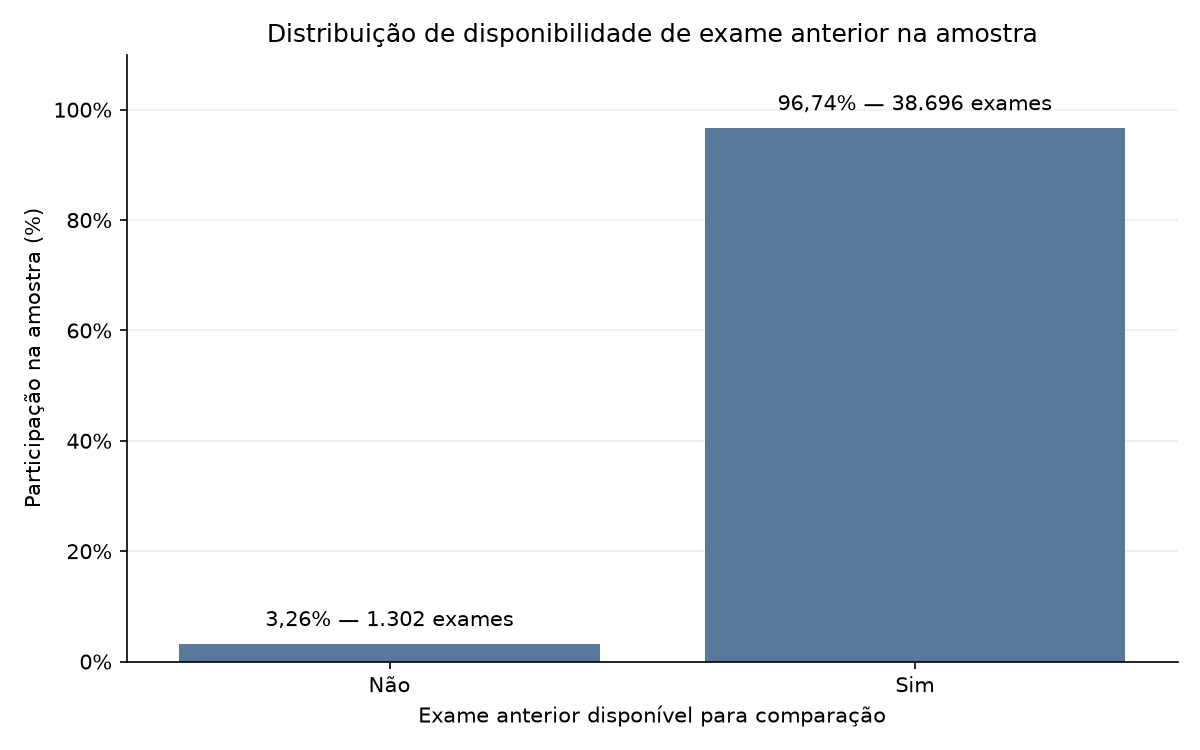

In [ ]:
# Distribuição de disponibilidade de exame anterior na amostra
# Indica imagens disponíveis para comparação, não apenas ter realizado mamografia.
# O percentual usa todos os exames, independentemente do diagnóstico.
# O grupo "Sim" inclui 4.680 respostas ausentes preenchidas no pré-processamento.
from matplotlib.ticker import FuncFormatter

fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(
    data=resumo_exame_anterior,
    x="Exame anterior disponível",
    y="Participação na amostra (%)",
    order=resumo_exame_anterior["Exame anterior disponível"].tolist(),
    color="#4C78A8",
    errorbar=None,
    ax=ax,
)

rotulos_distribuicao_exame_anterior = []
for percentual, quantidade in zip(
    resumo_exame_anterior["Participação na amostra (%)"],
    resumo_exame_anterior["Total de exames"],
):
    percentual_formatado = f"{percentual:.2f}".replace(".", ",")
    quantidade_formatada = f"{quantidade:,}".replace(",", ".")
    rotulos_distribuicao_exame_anterior.append(
        f"{percentual_formatado}% — {quantidade_formatada} exames"
    )

ax.bar_label(ax.containers[0], labels=rotulos_distribuicao_exame_anterior, padding=6)
ax.set_title("Distribuição de disponibilidade de exame anterior na amostra")
ax.set_xlabel("Exame anterior disponível para comparação")
ax.set_ylabel("Participação na amostra (%)")
ax.set_ylim(0, 110)
# A margem acima de 100% evita cortar o rótulo do grupo majoritário.
ax.yaxis.set_major_formatter(
    FuncFormatter(lambda valor, posicao: f"{valor:.0f}%")
)
ax.set_axisbelow(True)
ax.yaxis.grid(True, alpha=0.2)
sns.despine(ax=ax)
fig.tight_layout()
plt.show()


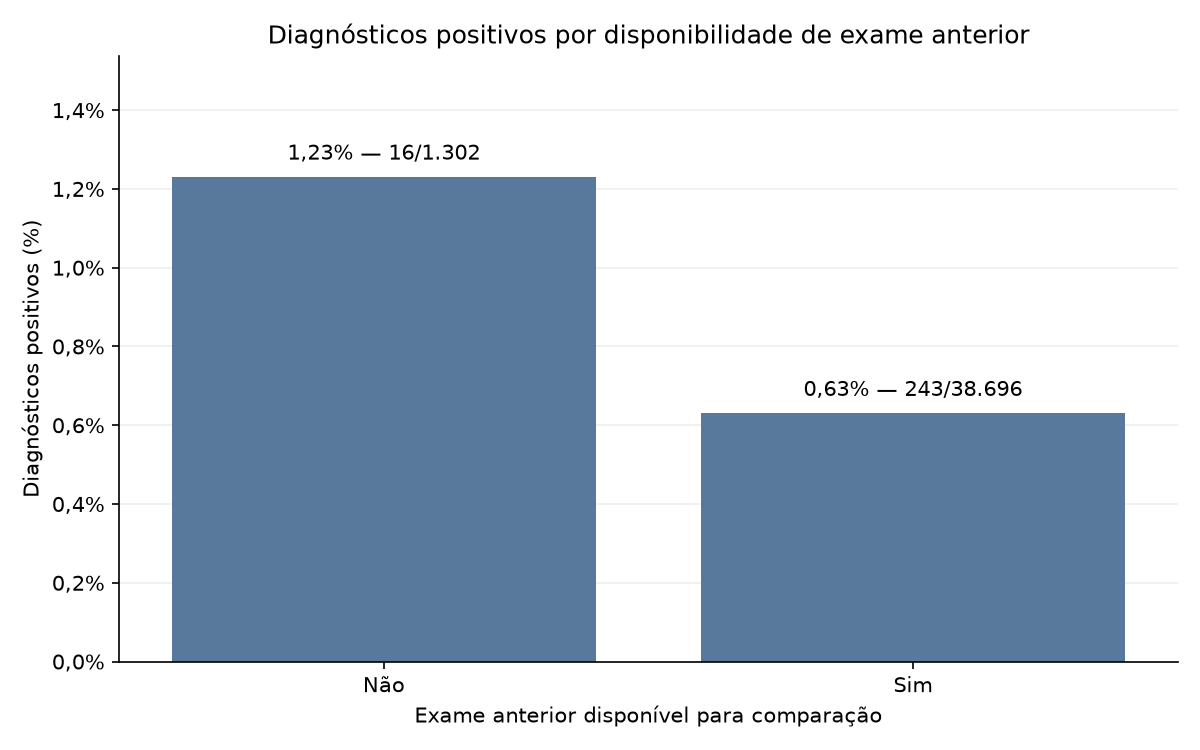

In [ ]:
# Percentual de diagnósticos positivos por disponibilidade de exame anterior
# Indica imagens anteriores disponíveis para comparação, não apenas ter feito mamografia.
# O grupo "Sim" inclui 4.680 respostas ausentes preenchidas no pré-processamento.
# A diferença observada não demonstra efeito causal da disponibilidade das imagens.
from matplotlib.ticker import FuncFormatter

fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(
    data=resumo_exame_anterior,
    x="Exame anterior disponível",
    y="Positivos (%)",
    order=resumo_exame_anterior["Exame anterior disponível"].tolist(),
    color="#4C78A8",
    errorbar=None,
    ax=ax,
)

rotulos_positivos_exame_anterior = []
for percentual, positivos, total in zip(
    resumo_exame_anterior["Positivos (%)"],
    resumo_exame_anterior["Positivos"],
    resumo_exame_anterior["Total de exames"],
):
    percentual_formatado = f"{percentual:.2f}".replace(".", ",")
    positivos_formatados = f"{positivos:,}".replace(",", ".")
    total_formatado = f"{total:,}".replace(",", ".")
    rotulos_positivos_exame_anterior.append(
        f"{percentual_formatado}% — {positivos_formatados}/{total_formatado}"
    )

ax.bar_label(ax.containers[0], labels=rotulos_positivos_exame_anterior, padding=6)
ax.set_title("Diagnósticos positivos por disponibilidade de exame anterior")
ax.set_xlabel("Exame anterior disponível para comparação")
ax.set_ylabel("Diagnósticos positivos (%)")
ax.set_ylim(0, resumo_exame_anterior["Positivos (%)"].max() * 1.25)
ax.yaxis.set_major_formatter(
    FuncFormatter(lambda valor, posicao: f"{valor:.1f}%".replace(".", ","))
)
ax.set_axisbelow(True)
ax.yaxis.grid(True, alpha=0.2)
sns.despine(ax=ax)
fig.tight_layout()
plt.show()


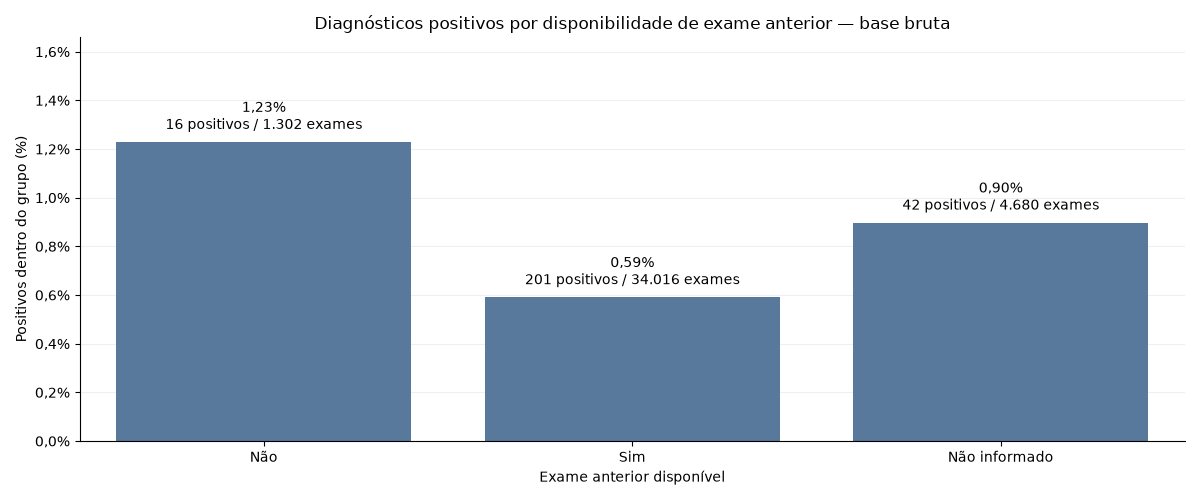

In [ ]:
# Exame anterior disponível na base bruta: respostas informadas e ausentes
# Mantém as ausências separadas; não altera df nem o pré-processamento.
# O percentual positivo usa o total de exames de cada grupo.
# Indica imagens anteriores disponíveis para comparação, não apenas ter realizado mamografia.
# "Não informado" reúne 42 positivos em 4.680 exames.
from matplotlib.ticker import FuncFormatter

exame_anterior_bruto = df_bruto["Comparison_Mammogram_From_Mammography"].map(
    {"No": "Não", "Yes": "Sim"}
).fillna("Não informado")

resumo_exame_anterior_bruto = (
    df_bruto.groupby(exame_anterior_bruto)["Is_Binary_Indicator_Of_Cancer_Diagnosis"]
    .agg(**{"Total de exames": "size", "Positivos": "sum"})
    .reindex(["Não", "Sim", "Não informado"])
    .rename_axis("Exame anterior disponível")
    .reset_index()
)
resumo_exame_anterior_bruto["Positivos (%)"] = (
    resumo_exame_anterior_bruto["Positivos"]
    / resumo_exame_anterior_bruto["Total de exames"] * 100
)

fig, ax = plt.subplots(figsize=(12, 5))
sns.barplot(
    data=resumo_exame_anterior_bruto,
    x="Exame anterior disponível", y="Positivos (%)",
    order=["Não", "Sim", "Não informado"],
    color="#4C78A8", errorbar=None, ax=ax,
)
rotulos_exame_anterior_bruto = [
    f"{percentual:.2f}%".replace(".", ",")
    + f"\n{int(positivos):,} positivos / {int(total):,} exames".replace(",", ".")
    for percentual, positivos, total in zip(
        resumo_exame_anterior_bruto["Positivos (%)"],
        resumo_exame_anterior_bruto["Positivos"],
        resumo_exame_anterior_bruto["Total de exames"],
    )
]
ax.bar_label(ax.containers[0], labels=rotulos_exame_anterior_bruto, padding=6)
ax.set_title("Diagnósticos positivos por disponibilidade de exame anterior — base bruta")
ax.set_xlabel("Exame anterior disponível")
ax.set_ylabel("Positivos dentro do grupo (%)")
ax.set_ylim(0, resumo_exame_anterior_bruto["Positivos (%)"].max() * 1.35)
ax.yaxis.set_major_formatter(FuncFormatter(lambda valor, posicao: f"{valor:.1f}%".replace(".", ",")))
ax.set_axisbelow(True)
ax.yaxis.grid(True, alpha=0.2)
sns.despine(ax=ax)
fig.tight_layout()
plt.show()


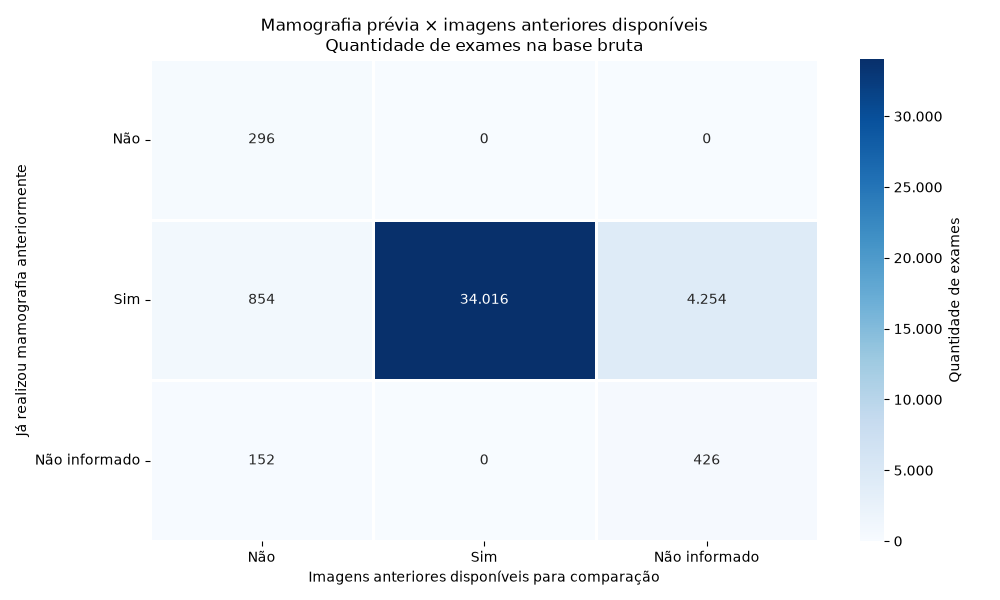

In [ ]:
# Mamografia prévia x disponibilidade de imagens anteriores — base bruta
# Já ter realizado mamografia não significa que as imagens estavam disponíveis.
# Mantém as ausências como "Não informado", sem alterar o pré-processamento.
# Cada célula conta exames, não pacientes distintas.
from matplotlib.ticker import FuncFormatter

ordem_previa_disponibilidade = ["Não", "Sim", "Não informado"]
previa_para_cruzamento = df_bruto["Binary_Indicator"].map(
    {"No": "Não", "Yes": "Sim"}
).fillna("Não informado")
disponibilidade_para_cruzamento = df_bruto["Comparison_Mammogram_From_Mammography"].map(
    {"No": "Não", "Yes": "Sim"}
).fillna("Não informado")
contagens_previa_disponibilidade = pd.crosstab(
    previa_para_cruzamento, disponibilidade_para_cruzamento,
    rownames=["Mamografia prévia"], colnames=["Imagens anteriores disponíveis"],
).reindex(index=ordem_previa_disponibilidade, columns=ordem_previa_disponibilidade, fill_value=0)
rotulos_previa_disponibilidade = contagens_previa_disponibilidade.apply(
    lambda coluna: coluna.map(lambda quantidade: f"{quantidade:,}".replace(",", "."))
)

fig, ax = plt.subplots(figsize=(10, 6))
sns.heatmap(
    contagens_previa_disponibilidade, annot=rotulos_previa_disponibilidade, fmt="",
    cmap="Blues", vmin=0, linewidths=1, linecolor="white",
    cbar_kws={"label": "Quantidade de exames", "format": FuncFormatter(
        lambda valor, posicao: f"{valor:,.0f}".replace(",", ".")
    )}, ax=ax,
)
ax.set_title("Mamografia prévia × imagens anteriores disponíveis\nQuantidade de exames na base bruta")
ax.set_xlabel("Imagens anteriores disponíveis para comparação")
ax.set_ylabel("Já realizou mamografia anteriormente")
ax.tick_params(axis="both", rotation=0)
fig.tight_layout()
plt.show()


In [ ]:
# Avaliação do radiologista x diagnóstico
# Os códigos 1–6 abaixo são internos ao arquivo processado, não os códigos BI-RADS originais.
# A avaliação do radiologista é diferente do diagnóstico de câncer em até um ano (alvo).
alvo = "Is_Binary_Indicator_Of_Cancer_Diagnosis"
coluna_avaliacao_radiologista = "Radiologists_Assessment"

categorias_avaliacao_radiologista = {
    1: "Negativo",
    2: "Achados benignos",
    3: "Provavelmente benigno",
    4: "Necessita de imagens adicionais",
    5: "Anormalidade suspeita",
    6: "Altamente sugestivo de malignidade",
}

linhas_avaliacao_radiologista = []

for codigo, categoria in categorias_avaliacao_radiologista.items():
    exames = df.loc[df[coluna_avaliacao_radiologista] == codigo]
    total = len(exames)
    negativos = (exames[alvo] == 0).sum()
    positivos = (exames[alvo] == 1).sum()

    linhas_avaliacao_radiologista.append({
        "Avaliação do radiologista": categoria,
        "Total de exames": total,
        "Participação na amostra (%)": total / len(df) * 100,
        "Negativos": negativos,
        "Negativos (%)": negativos / total * 100,
        "Positivos": positivos,
        "Positivos (%)": positivos / total * 100,
    })

resumo_avaliacao_radiologista = pd.DataFrame(linhas_avaliacao_radiologista).round(2)
resumo_avaliacao_radiologista


Avaliação do radiologista,Total de exames,Participação na amostra (%),Negativos,Negativos (%),Positivos,Positivos (%)
Negativo,26031,65.08,26011,99.92,20,0.08
Achados benignos,10717,26.79,10705,99.89,12,0.11
Provavelmente benigno,139,0.35,138,99.28,1,0.72
Necessita de imagens adicionais,3049,7.62,2851,93.51,198,6.49
Anormalidade suspeita,57,0.14,33,57.89,24,42.11
Altamente sugestivo de malignidade,5,0.01,1,20.00,4,80.00


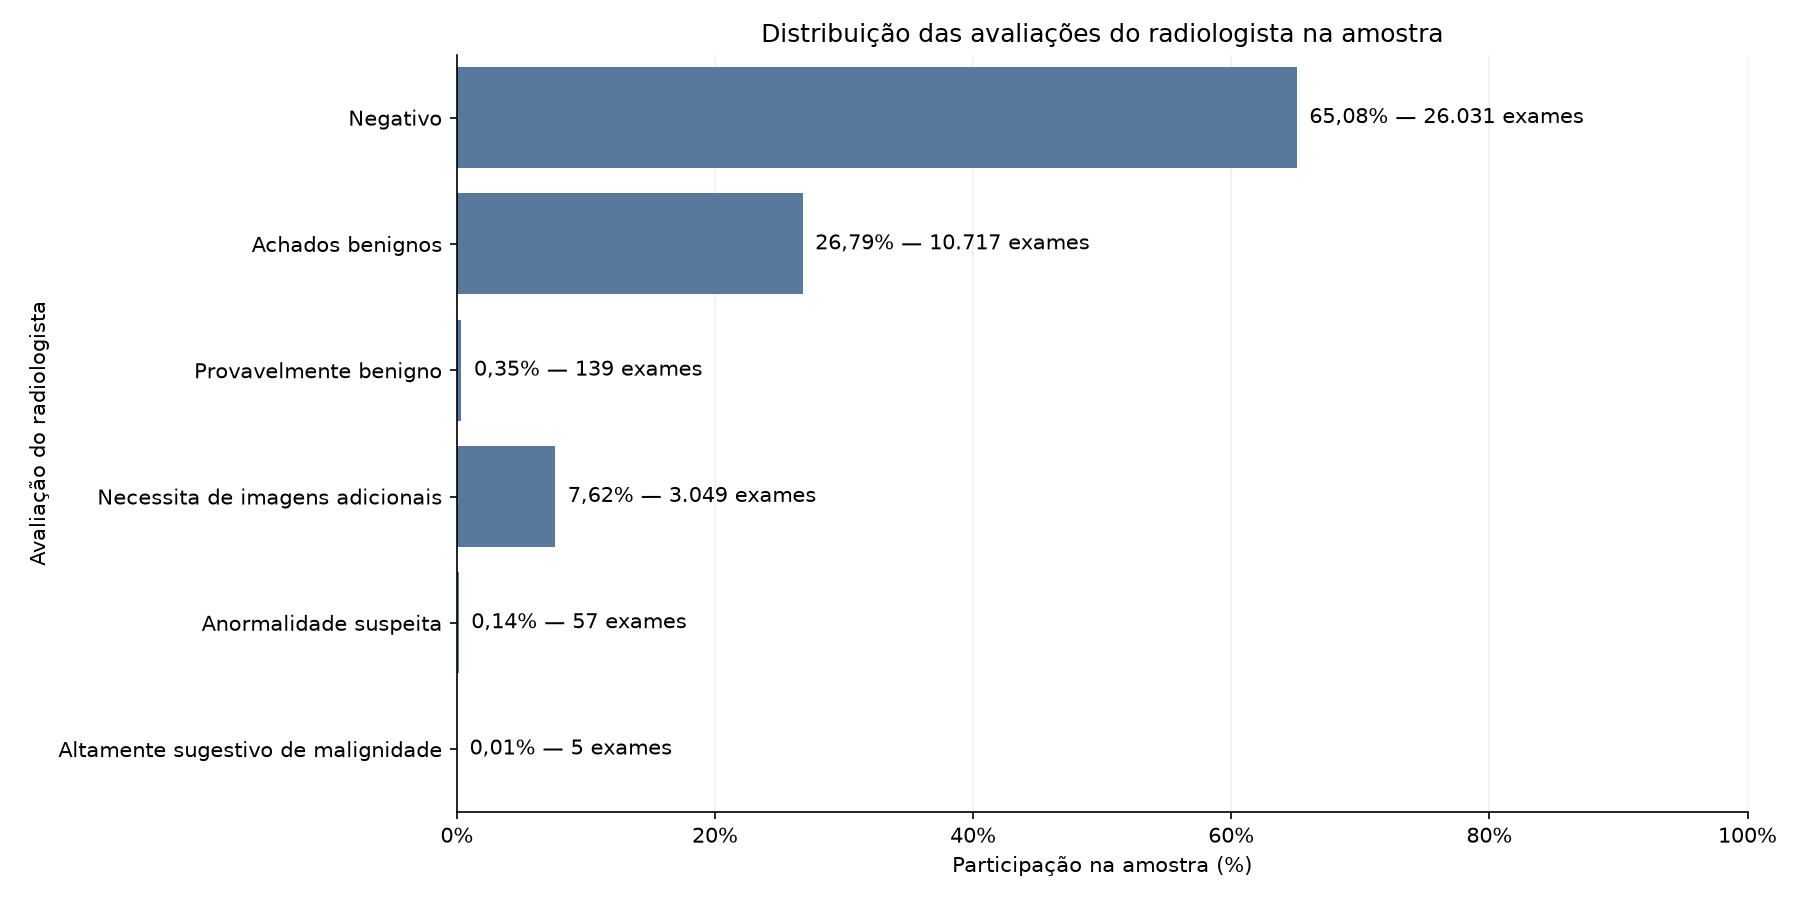

In [ ]:
# Distribuição das avaliações do radiologista na amostra
# Usamos os nomes das categorias; os códigos internos não são os BI-RADS originais.
# O percentual usa todos os exames da amostra, independentemente do diagnóstico.
from matplotlib.ticker import FuncFormatter

fig, ax = plt.subplots(figsize=(12, 6))
sns.barplot(
    data=resumo_avaliacao_radiologista,
    x="Participação na amostra (%)",
    y="Avaliação do radiologista",
    order=resumo_avaliacao_radiologista["Avaliação do radiologista"].tolist(),
    orient="h",
    color="#4C78A8",
    errorbar=None,
    ax=ax,
)

rotulos_distribuicao_avaliacao_radiologista = []
for percentual, quantidade in zip(
    resumo_avaliacao_radiologista["Participação na amostra (%)"],
    resumo_avaliacao_radiologista["Total de exames"],
):
    percentual_formatado = f"{percentual:.2f}".replace(".", ",")
    quantidade_formatada = f"{quantidade:,}".replace(",", ".")
    rotulos_distribuicao_avaliacao_radiologista.append(
        f"{percentual_formatado}% — {quantidade_formatada} exames"
    )

ax.bar_label(ax.containers[0], labels=rotulos_distribuicao_avaliacao_radiologista, padding=6)
ax.set_title("Distribuição das avaliações do radiologista na amostra")
ax.set_xlabel("Participação na amostra (%)")
ax.set_ylabel("Avaliação do radiologista")
ax.set_xlim(0, 100)
ax.xaxis.set_major_formatter(
    FuncFormatter(lambda valor, posicao: f"{valor:.0f}%")
)
ax.set_axisbelow(True)
ax.xaxis.grid(True, alpha=0.2)
sns.despine(ax=ax)
fig.tight_layout()
plt.show()


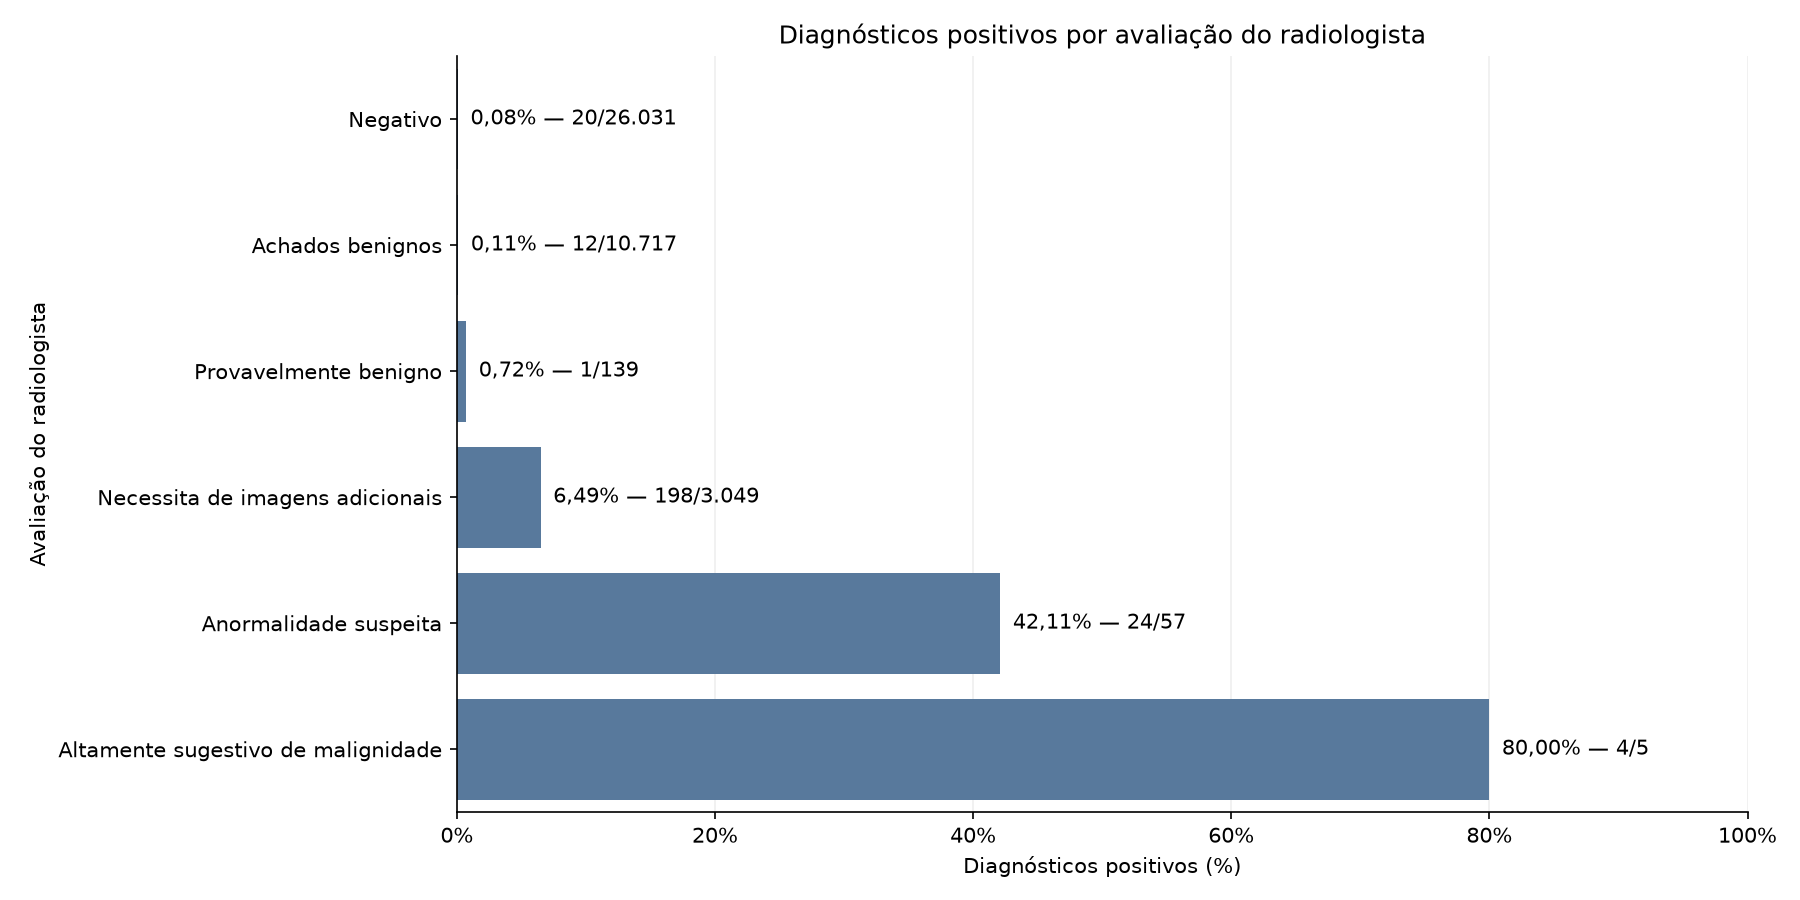

In [ ]:
# Percentual de diagnósticos positivos por avaliação do radiologista
# A avaliação radiológica é diferente do diagnóstico de câncer em até um ano (alvo).
# Os códigos internos 1–6 não são os códigos BI-RADS originais; usamos os nomes das categorias.
# Na categoria altamente sugestiva de malignidade, 80% correspondem a apenas 4 de 5 exames.
from matplotlib.ticker import FuncFormatter

fig, ax = plt.subplots(figsize=(12, 6))
sns.barplot(
    data=resumo_avaliacao_radiologista,
    x="Positivos (%)",
    y="Avaliação do radiologista",
    order=resumo_avaliacao_radiologista["Avaliação do radiologista"].tolist(),
    orient="h",
    color="#4C78A8",
    errorbar=None,
    ax=ax,
)

rotulos_positivos_avaliacao_radiologista = []
for percentual, positivos, total in zip(
    resumo_avaliacao_radiologista["Positivos (%)"],
    resumo_avaliacao_radiologista["Positivos"],
    resumo_avaliacao_radiologista["Total de exames"],
):
    percentual_formatado = f"{percentual:.2f}".replace(".", ",")
    positivos_formatados = f"{positivos:,}".replace(",", ".")
    total_formatado = f"{total:,}".replace(",", ".")
    rotulos_positivos_avaliacao_radiologista.append(
        f"{percentual_formatado}% — {positivos_formatados}/{total_formatado}"
    )

ax.bar_label(ax.containers[0], labels=rotulos_positivos_avaliacao_radiologista, padding=6)
ax.set_title("Diagnósticos positivos por avaliação do radiologista")
ax.set_xlabel("Diagnósticos positivos (%)")
ax.set_ylabel("Avaliação do radiologista")
ax.set_xlim(0, 100)
ax.xaxis.set_major_formatter(
    FuncFormatter(lambda valor, posicao: f"{valor:.0f}%")
)
ax.set_axisbelow(True)
ax.xaxis.grid(True, alpha=0.2)
sns.despine(ax=ax)
fig.tight_layout()
plt.show()


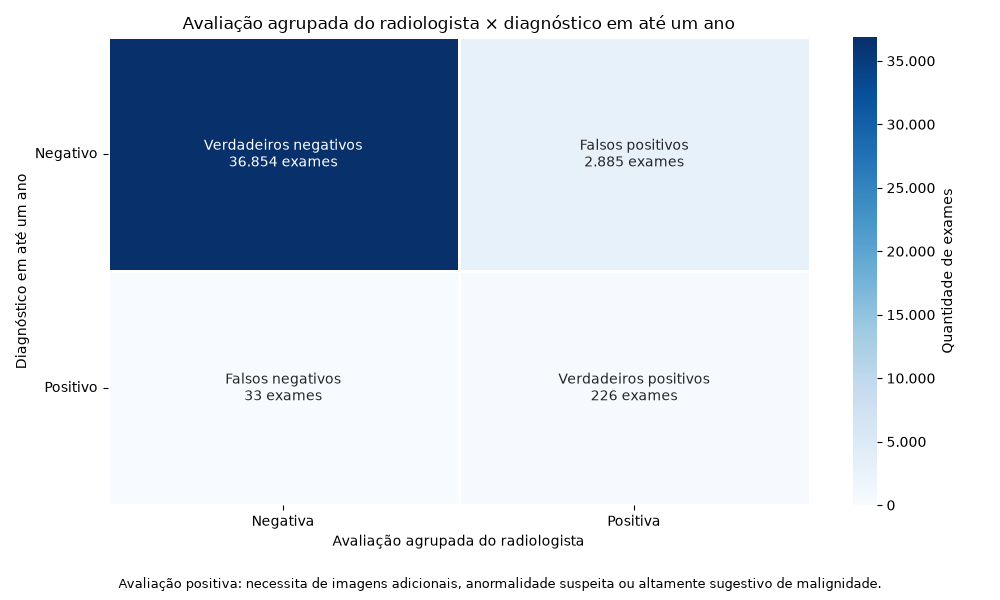

In [ ]:
# Avaliação agrupada do radiologista x diagnóstico em até um ano
# Regra exploratória aprovada: positiva = imagens adicionais, suspeita ou altamente sugestiva.
# Negativa = negativo, achados benignos ou provavelmente benigno.
# Os códigos 4, 5 e 6 são internos ao arquivo processado, não BI-RADS originais.
# A matriz conta exames; a avaliação agrupada não é um modelo treinado.
from matplotlib.ticker import FuncFormatter

codigos_avaliacao_positiva = [4, 5, 6]
avaliacao_agrupada = df["Radiologists_Assessment"].isin(codigos_avaliacao_positiva).map(
    {False: "Negativa", True: "Positiva"}
)
diagnostico_para_matriz = df["Is_Binary_Indicator_Of_Cancer_Diagnosis"].map(
    {0: "Negativo", 1: "Positivo"}
)
matriz_avaliacao_diagnostico = pd.crosstab(
    diagnostico_para_matriz, avaliacao_agrupada,
    rownames=["Diagnóstico em até um ano"], colnames=["Avaliação agrupada"],
).reindex(index=["Negativo", "Positivo"], columns=["Negativa", "Positiva"], fill_value=0)
rotulos_matriz_avaliacao = pd.DataFrame(
    [["Verdadeiros negativos", "Falsos positivos"],
     ["Falsos negativos", "Verdadeiros positivos"]],
    index=matriz_avaliacao_diagnostico.index, columns=matriz_avaliacao_diagnostico.columns,
)
for diagnostico in matriz_avaliacao_diagnostico.index:
    for avaliacao in matriz_avaliacao_diagnostico.columns:
        quantidade = matriz_avaliacao_diagnostico.loc[diagnostico, avaliacao]
        rotulos_matriz_avaliacao.loc[diagnostico, avaliacao] += (
            "\n" + f"{quantidade:,} exames".replace(",", ".")
        )

fig, ax = plt.subplots(figsize=(10, 6))
sns.heatmap(
    matriz_avaliacao_diagnostico, annot=rotulos_matriz_avaliacao, fmt="",
    cmap="Blues", vmin=0, linewidths=1, linecolor="white",
    cbar_kws={"label": "Quantidade de exames", "format": FuncFormatter(
        lambda valor, posicao: f"{valor:,.0f}".replace(",", ".")
    )}, ax=ax,
)
ax.set_title("Avaliação agrupada do radiologista × diagnóstico em até um ano")
ax.set_xlabel("Avaliação agrupada do radiologista")
ax.set_ylabel("Diagnóstico em até um ano")
ax.tick_params(axis="both", rotation=0)
fig.text(
    0.5, 0.02,
    "Avaliação positiva: necessita de imagens adicionais, anormalidade suspeita ou altamente sugestivo de malignidade.",
    ha="center", fontsize=9,
)
fig.tight_layout(rect=[0, 0.06, 1, 1])
plt.show()


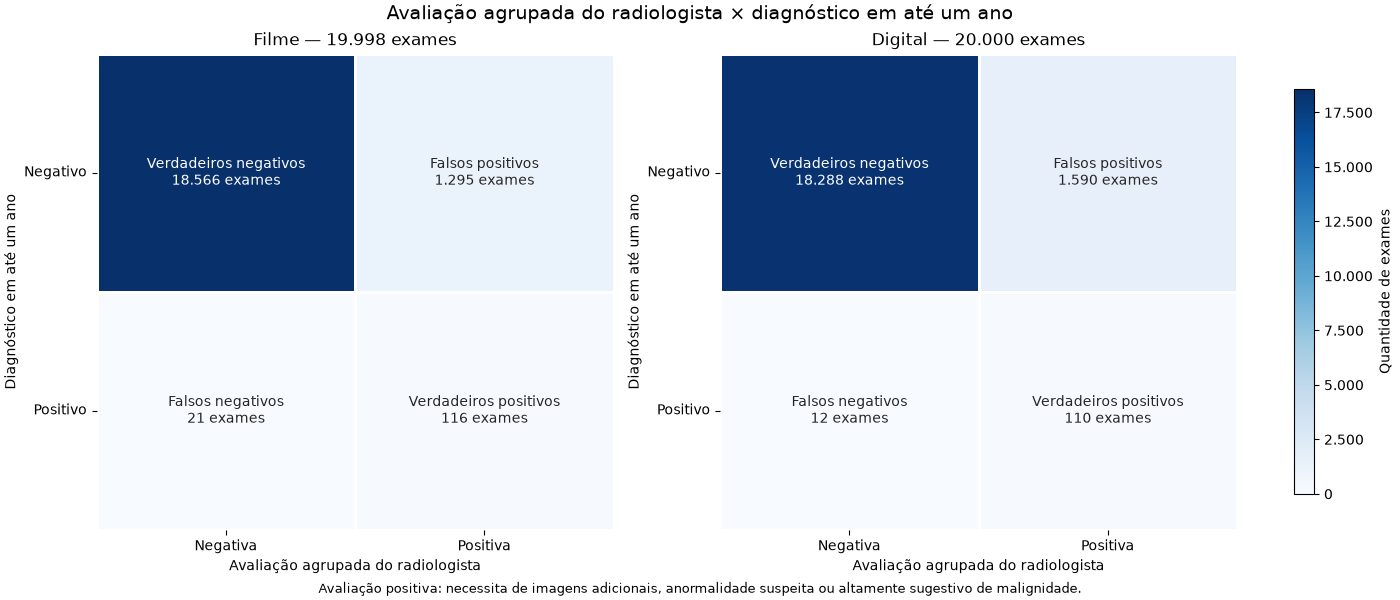

In [ ]:
# Avaliação agrupada x diagnóstico: filme e digital
# Mantém a regra exploratória da matriz geral e a mesma escala nas duas figuras.
# Positiva = imagens adicionais, suspeita ou altamente sugestiva (códigos internos 4/5/6).
# Negativa = negativo, achados benignos ou provavelmente benigno.
# Contagens por exame; esta comparação não ajusta diferenças entre os grupos.
from matplotlib.ticker import FuncFormatter

matrizes_avaliacao_por_tipo = {}
for codigo, tipo in categorias_tipo_mamografia.items():
    mascara_tipo = df["Is_Film_Or_Digital_Mammogram"].eq(codigo)
    matrizes_avaliacao_por_tipo[tipo] = pd.crosstab(
        diagnostico_para_matriz.loc[mascara_tipo], avaliacao_agrupada.loc[mascara_tipo],
        rownames=["Diagnóstico em até um ano"], colnames=["Avaliação agrupada"],
    ).reindex(index=["Negativo", "Positivo"], columns=["Negativa", "Positiva"], fill_value=0)

limite_cor_matrizes_tipo = max(matriz.to_numpy().max() for matriz in matrizes_avaliacao_por_tipo.values())
fig, eixos_matrizes_tipo = plt.subplots(1, 2, figsize=(14, 6), layout="constrained")
for ax, (tipo, matriz) in zip(eixos_matrizes_tipo, matrizes_avaliacao_por_tipo.items()):
    rotulos = pd.DataFrame(
        [["Verdadeiros negativos", "Falsos positivos"],
         ["Falsos negativos", "Verdadeiros positivos"]],
        index=matriz.index, columns=matriz.columns,
    )
    for diagnostico in matriz.index:
        for avaliacao in matriz.columns:
            rotulos.loc[diagnostico, avaliacao] += (
                "\n" + f"{matriz.loc[diagnostico, avaliacao]:,} exames".replace(",", ".")
            )
    sns.heatmap(
        matriz, annot=rotulos, fmt="", cmap="Blues",
        vmin=0, vmax=limite_cor_matrizes_tipo,
        linewidths=1, linecolor="white", cbar=False, ax=ax,
    )
    total_formatado = f"{matriz.to_numpy().sum():,}".replace(",", ".")
    ax.set_title(f"{tipo} — {total_formatado} exames")
    ax.set_xlabel("Avaliação agrupada do radiologista")
    ax.set_ylabel("Diagnóstico em até um ano")
    ax.tick_params(axis="both", rotation=0)
fig.colorbar(
    eixos_matrizes_tipo[0].collections[0], ax=list(eixos_matrizes_tipo),
    label="Quantidade de exames", shrink=0.85,
    format=FuncFormatter(lambda valor, posicao: f"{valor:,.0f}".replace(",", ".")),
)
fig.suptitle("Avaliação agrupada do radiologista × diagnóstico em até um ano", fontsize=14)
fig.supxlabel(
    "Avaliação positiva: necessita de imagens adicionais, anormalidade suspeita ou altamente sugestivo de malignidade.",
    fontsize=9,
)
plt.show()
